# Original Sniper Break-Even strategy

**October 10, 2026, 16:00–17:00 UTC (19:00–20:00 Kyiv) launch cohort only.**
The study reads the original strategy's saved native engine results for 2,342
launches. Its 38 signals, 18 buy fills, failed/rejected entries and open
positions remain visible. Post-hour observations follow only these launches
through their outcomes. This is the previously investigated development sample.

The main result uses conditional replay that carries own reserve impact forward
and preserves other traders' **observed sell fractions**. This is a modeled
order-sizing assumption; unknown inventory or execution context remains
unresolved. Original results under other execution assumptions appear in a
separate appendix for this same hour. They are not added together.

The original rule set is retained. This notebook reads preserved results and
does not run a strategy or query ClickHouse/RPC. Earlier comparison notebooks,
revised runs and raw data remain archived separately.

In [1]:
"""Read and plot preserved native results without rerunning a strategy."""
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path
import csv
import gzip
import hashlib
import html
import json
import sys

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/backtest').is_dir() and (p / 'var/dnipro').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from backtest.domain.hashing import domain_digest

RUN_ROOT = ROOT / 'var/dnipro/sniper-window-redesign-v1'
EXPORT = ROOT / 'var/dnipro/sniper-original-position-charts-20261014-v4'
EXPORT.mkdir(parents=True, exist_ok=True)
SOL = 'So11111111111111111111111111111111111111112'
LAMPORTS = 1_000_000_000
COHORTS = {
    'development': ('October 10, 16:00–17:00 UTC', '2026-10-10-1600-1700'),
}
RUN_IDS = ['development-conditional_fraction-before']
COLORS = {'before': '#69738b', 'after': '#1768b3'}
GOOD, BAD = '#14825e', '#c13e46'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = [f for f in ['DejaVu Sans', 'Hiragino Sans GB',
                                           'Hiragino Sans'] if f in fonts]
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', 65)


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def csv_rows(path):
    with Path(path).open() as stream:
        return list(csv.DictReader(stream))


def utc(value):
    return datetime.fromtimestamp(int(value), timezone.utc).isoformat()


def stamp(value):
    return int(datetime.fromisoformat(str(value).replace('Z', '+00:00'))
               .replace(tzinfo=timezone.utc).timestamp())


def linked_table(frame):
    data = frame.copy()
    for field in data.select_dtypes(include=['object', 'str']).columns:
        data[field] = data[field].map(lambda x: html.escape(str(x)) if pd.notna(x) else '')
    if 'gmgn_url' in frame:
        data['gmgn_url'] = [f'<a href="{html.escape(url, quote=True)}" target="_blank" '
                            'rel="noopener">GMGN</a>' for url in frame['gmgn_url']]
    display(HTML('<div style="max-height:650px;overflow:auto">' +
                 data.to_html(index=False, escape=False, na_rep='—',
                              float_format=lambda x: f'{x:,.9f}') + '</div>'))


def finish_plot(fig, filename):
    fig.savefig(EXPORT / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def read_gz(path):
    with gzip.open(path, 'rt') as stream:
        for line in stream:
            yield json.loads(line)


def verify_and_load():
    receipt = json.loads((RUN_ROOT / 'comparison_receipt.json').read_text())
    assert receipt['complete'] and receipt['runs'] == 30
    for name, digest in receipt['files'].items():
        assert sha(RUN_ROOT / name) == digest, name
    for name in RUN_IDS:
        assert sha(RUN_ROOT / name / 'result.json') == receipt['output_result_hashes'][name], name
    runs, positions, summaries = {}, [], []
    for name in RUN_IDS:
        folder = RUN_ROOT / name
        manifest = json.loads((folder / 'manifest.json').read_text())
        assert manifest['complete']
        for filename, digest in manifest['files'].items():
            assert sha(folder / filename) == digest, (name, filename)
        r = json.loads((folder / 'result.json').read_text())
        s = r['summary']
        assert s['own_reserve_impact_propagated'] and s['synthetic_shortfall_lamports'] == 0
        if s['proven_empty_slots']:
            assert s['proven_empty_slots'] == [455328000]
            assert sha(ROOT / 'var/dnipro/sniper-gap-455328000.json') == s['empty_block_evidence_sha256']
        for tx in r['ledger']:
            totals = defaultdict(int)
            for posting in tx['postings']:
                totals[posting['asset_id']] += posting['amount_atomic']
            assert all(v == 0 for v in totals.values()), tx['transaction_id']
        actual = sum(p.get('closed_pnl_lamports') or 0 for p in r['positions'])
        actual -= sum(p['failed_execution_cost_lamports'] for p in r['positions']
                      if not p['entry_cash_lamports'])
        assert actual == s['realized_net_pnl_lamports']
        cohort, version = name.split('-')[0], 'original'
        runs[name] = r
        summaries.append(dict(run=name, sample=COHORTS[cohort][0], version=version,
                              start_utc=s['cohort_start_utc'], end_utc=s['cohort_end_utc'],
                              launches=s['cohort_launches'], filled=s['filled_entries'],
                              closed=s['closed_positions'], open=s['open_positions'],
                              net_closed_pnl_SOL=actual / LAMPORTS,
                              open_cost_SOL=s['open_cash_cost_lamports'] / LAMPORTS,
                              publication_gaps=len(s['publication_gaps']),
                              repricing_conflicts=s['conditional_repricing_errors']))
        for p in r['positions']:
            if 'signal_slot' not in p:
                continue
            outcome = ('Profitable' if p['closed_pnl_lamports'] > 0 else
                       'Losing' if p['closed_pnl_lamports'] < 0 else 'Breakeven') \
                if p['status'] == 'CLOSED' else {
                    'OPEN': 'Open / unresolved', 'ENTRY_FAILED': 'Entry failed',
                    'ENTRY_REJECTED': 'Entry rejected',
                }.get(p['status'], p['status'])
            positions.append(dict(
                run=name, sample=COHORTS[cohort][0], version=version,
                token=p['symbol'].strip(), mint=p['mint'], gmgn_url=p['gmgn_url'],
                outcome=outcome, status=p['status'], reason=p['reason'],
                signal_slot=p['signal_slot'], signal_utc=utc(p['signal_time']),
                entry_slot=p.get('entry_slot'), exit_slot=p.get('exit_slot'),
                entry_SOL=p['entry_cash_lamports'] / LAMPORTS,
                exit_receipt_SOL=p.get('exit_receipt_lamports', 0) / LAMPORTS
                    if p['status'] == 'CLOSED' else None,
                net_pnl_SOL=p['closed_pnl_lamports'] / LAMPORTS
                    if p['status'] == 'CLOSED' else
                    -p['failed_execution_cost_lamports'] / LAMPORTS
                    if not p['entry_cash_lamports'] else None,
                failed_execution_fees_SOL=p['failed_execution_cost_lamports'] / LAMPORTS,
                open_cost_SOL=(p['entry_cash_lamports'] + p['failed_execution_cost_lamports'])
                    / LAMPORTS if p['status'] == 'OPEN' else 0,
                remaining_tokens_raw=p['remaining_tokens_atomic'],
                holding_seconds=p.get('exit_time', p.get('entry_time', 0))
                    - p.get('entry_time', 0) if p['status'] == 'CLOSED' else None,
                creator=p['creator'], reference_wallet=p.get('sniper_wallet'),
            ))
    original = runs[RUN_IDS[0]]['summary']
    assert all(s['cohort_start_utc'] == '2026-10-10T16:00:00Z'
               and s['cohort_end_utc'] == '2026-10-10T17:00:00Z' for s in [original])
    for field, value in dict(require_creator_never_bought=0, confirmation_slots=0,
                             confirmation_new_buyers=0, confirmation_net_lamports=0,
                             maximum_entry_budget_lamports=0, stop_loss_bps=0,
                             entry_window_slots=0, holding_seconds=300).items():
        assert original['policy'][field] == value, field
    return runs, pd.DataFrame(positions), pd.DataFrame(summaries), receipt


def load_source_context(runs):
    clocks, tapes, source_hashes = {}, defaultdict(list), {}
    for cohort, (_, snapshot) in COHORTS.items():
        wanted = {p['mint'] for name, r in runs.items() if name.startswith(cohort + '-')
                  for p in r['positions'] if 'signal_slot' in p}
        folder = ROOT.parent / 'solana-live-indexer/research/sniper_break_even/data' / snapshot
        manifest = json.loads((folder / 'manifest.json').read_text())
        assert manifest['complete'] and manifest['publication_unchanged']
        source_hashes[cohort] = sha(folder / 'manifest.json')
        clock, count = {}, 0
        for part in manifest['parts']:
            if not part['name'].endswith(('-clock', '-trades')):
                continue
            path = folder / 'snapshot' / part['file']
            assert sha(path) == part['file_sha256'], (cohort, part['file'])
            read_count = 0
            for row in read_gz(path):
                read_count += 1
                if part['name'].endswith('-clock'):
                    clock[int(row['slot'])] = stamp(row['observed_block_time'])
                else:
                    count += 1
                    if row['mint'] in wanted:
                        tapes[cohort, row['mint']].append(row)
            assert read_count == part['rows']
        reference = next(r for name, r in runs.items() if name.startswith(cohort + '-'))
        assert count == reference['summary']['retained_input_trade_events']
        clocks[cohort] = clock
    for values in tapes.values():
        values.sort(key=lambda x: (x['slot'], x['tx_idx'], tuple(x['instruction_path']), x['event_uid']))
    return clocks, tapes, source_hashes


def native_order_context(run_id, r):
    audit = csv_rows(RUN_ROOT / run_id / 'order_audit.csv')
    mapping = {f['order_id']: (f['pool_id'], 'BUY' if f['sold_asset_id'] == SOL else 'SELL')
               for f in r['fills']}
    component = domain_digest('dnipro.configured-sniper-window.v1', r['summary']['policy']).hex
    signaled = [p for p in r['positions'] if 'signal_slot' in p]
    for a in audit:
        order_id = a['order_id']
        if order_id in mapping:
            continue
        boundary = int(a['boundary_ordinal'])
        for p in signaled:
            if p['signal_slot'] == boundary >> 32:
                digest = domain_digest('dnipro.sniper-order.v1', dict(
                    mint=p['mint'], side='BUY', boundary=boundary, attempt=0, component=component)).hex
                if digest == order_id:
                    mapping[order_id] = p['mint'], 'BUY'
            if p.get('entry_slot', 10**15) <= boundary >> 32:
                for attempt in range(1, p['exit_attempts'] + 1):
                    digest = domain_digest('dnipro.sniper-order.v1', dict(
                        mint=p['mint'], side='SELL', boundary=boundary,
                        attempt=attempt, component=component)).hex
                    if digest == order_id:
                        mapping[order_id] = p['mint'], 'SELL'
    assert all(a['order_id'] in mapping for a in audit), run_id
    return audit, mapping


def ledger_frames(run_id, r, mapping, clock):
    rows, postings = [], []
    for tx in r['ledger']:
        mint, side = mapping[tx['correlation_id']]
        delta = sum(p['amount_atomic'] for p in tx['postings'] if p['asset_id'] == SOL
                    and p['account_kind'] in ['PORTFOLIO_AVAILABLE', 'PORTFOLIO_RESERVED'])
        fees = sum(p['amount_atomic'] for p in tx['postings'] if p['asset_id'] == SOL
                   and p['account_kind'] == 'NETWORK_FEE')
        slot = tx['boundary_ordinal'] >> 32
        rows.append(dict(run=run_id, mint=mint, side=side, slot=slot,
                         boundary_ordinal=tx['boundary_ordinal'], time=clock[slot],
                         utc=utc(clock[slot]), order_id=tx['correlation_id'],
                         reason=tx['reason'], cash_delta_lamports=delta,
                         cash_delta_SOL=delta / LAMPORTS, network_fee_SOL=fees / LAMPORTS))
        postings.extend(dict(run=run_id, mint=mint, side=side, slot=slot,
                             order_id=tx['correlation_id'], reason=tx['reason'], **p)
                        for p in tx['postings'])
    frame = pd.DataFrame(rows).sort_values('boundary_ordinal', kind='stable')
    s = r['summary']
    assert int(frame['cash_delta_lamports'].sum()) == (
        s['realized_net_pnl_lamports'] - s['open_cash_cost_lamports'])
    for p in r['positions']:
        if 'signal_slot' not in p:
            continue
        expected = p['closed_pnl_lamports'] if p['status'] == 'CLOSED' else \
            -p['entry_cash_lamports'] - p['failed_execution_cost_lamports']
        assert int(frame.loc[frame['mint'] == p['mint'], 'cash_delta_lamports'].sum()) == expected
    return frame, pd.DataFrame(postings)


def pnl_events(run_id, r, ledger):
    events = []
    for p in r['positions']:
        if p['status'] == 'CLOSED':
            events.append(dict(run=run_id, mint=p['mint'], token=p['symbol'].strip(),
                               slot=p['exit_slot'], time=p['exit_time'],
                               pnl_lamports=p['closed_pnl_lamports'], event='Position closed'))
        elif not p['entry_cash_lamports'] and p['failed_execution_cost_lamports']:
            for row in ledger[(ledger['mint'] == p['mint']) &
                              (ledger['cash_delta_lamports'] < 0)].to_dict('records'):
                events.append(dict(run=run_id, mint=p['mint'], token=p['symbol'].strip(),
                                   slot=row['slot'], time=row['time'],
                                   pnl_lamports=row['cash_delta_lamports'], event='Failed entry fee'))
    frame = pd.DataFrame(events).sort_values(['slot', 'mint'], kind='stable')
    assert int(frame['pnl_lamports'].sum()) == r['summary']['realized_net_pnl_lamports']
    frame['pnl_SOL'] = frame['pnl_lamports'] / LAMPORTS
    frame['cumulative_pnl_SOL'] = frame['pnl_lamports'].cumsum() / LAMPORTS
    frame['utc'] = frame['time'].map(utc)
    return frame


def entry_exit_records(run_id):
    """Native fills supply marker prices; no fills are inferred from history."""
    r = RUNS[run_id]
    rows = {p['mint']: p for p in r['positions']}
    cohort = run_id.split('-')[0]
    markers = []
    for fill in r['fills']:
        mint, order_id = fill['pool_id'], fill['order_id']
        p = rows[mint]
        side = 'BUY' if fill['sold_asset_id'] == SOL else 'SELL'
        venue = POSTINGS[run_id]
        cash = venue[(venue['order_id'] == order_id) & (venue['reason'] == 'ORDER_SETTLEMENT') &
                     (venue['account_kind'] == 'VENUE') & (venue['asset_id'] == SOL)]
        assert len(cash) == 1, order_id
        signed_curve = int(cash['amount_atomic'].iloc[0])
        assert signed_curve > 0 if side == 'BUY' else signed_curve < 0
        tokens = int(fill['amount_out_atomic'] if side == 'BUY' else fill['amount_in_atomic'])
        first = TAPES[cohort, mint][0]
        reference = int(first['virtual_quote']) / int(first['virtual_base'])
        average_index = abs(signed_curve) / tokens / reference * 100
        slot = fill['boundary_ordinal'] >> 32
        field = 'entry' if side == 'BUY' else 'exit'
        assert slot == p[field + '_slot']
        markers.append(dict(mint=mint, token=p['symbol'].strip(), side=side, slot=slot,
                            utc=utc(p[field + '_time']), order_id=order_id,
                            average_curve_price_index=average_index,
                            gross_curve_SOL=abs(signed_curve) / LAMPORTS, tokens_raw=tokens))
    marker_frame = pd.DataFrame(markers)
    signaled = []
    groups = {'Profitable': 'Profitable', 'Losing': 'Unprofitable',
              'Open / unresolved': 'Undecided', 'Entry failed': 'Entry failed',
              'Entry rejected': 'Entry rejected', 'Breakeven': 'Breakeven'}
    for row in POSITIONS.to_dict('records'):
        p = rows[row['mint']]
        native = marker_frame[marker_frame['mint'] == row['mint']]
        buy, sell = native[native['side'] == 'BUY'], native[native['side'] == 'SELL']
        assert len(buy) == int(p['entry_cash_lamports'] > 0)
        assert len(sell) == int(p['status'] == 'CLOSED')
        row.update(group=groups[row['outcome']],
                   entry_utc=utc(p['entry_time']) if len(buy) else None,
                   exit_utc=utc(p['exit_time']) if len(sell) else None,
                   entry_average_curve_price_index=float(buy['average_curve_price_index'].iloc[0]) if len(buy) else None,
                   exit_average_curve_price_index=float(sell['average_curve_price_index'].iloc[0]) if len(sell) else None,
                   entry_order_id=buy['order_id'].iloc[0] if len(buy) else None,
                   exit_order_id=sell['order_id'].iloc[0] if len(sell) else None)
        signaled.append(row)
    frame = pd.DataFrame(signaled).sort_values(['signal_utc', 'mint'])
    for field in ['signal_slot', 'entry_slot', 'exit_slot']:
        frame[field] = frame[field].astype('Int64')
    return frame, marker_frame


def draw_entry_exit(ax, run_id, mint):
    p = next(p for p in RUNS[run_id]['positions'] if p['mint'] == mint)
    launch = p['launch_slot']
    cohort = run_id.split('-')[0]
    all_tape = pd.DataFrame(TAPES[cohort, mint])
    markers = FILL_MARKERS[FILL_MARKERS['mint'] == mint]
    audit = [a for a in AUDITS[run_id] if ORDER_MAPS[run_id][a['order_id']][0] == mint]
    attempts = [a for a in audit if a['record_type'] in
                ['ORDER_REJECTED', 'ORDER_EXECUTION_FAILED_AND_RELEASED']]
    if p['status'] == 'CLOSED':
        end = p['exit_slot'] + 30
    elif p['status'] == 'OPEN':
        end = max(p['entry_slot'], int(all_tape['slot'].max()))
    else:
        end = max([p['signal_slot'], *[int(a['boundary_ordinal']) >> 32 for a in attempts]]) + 30
    tape = all_tape[all_tape['slot'] <= end]
    reference = int(all_tape.iloc[0]['virtual_quote']) / int(all_tape.iloc[0]['virtual_base'])
    index = tape['virtual_quote'].astype(float) / tape['virtual_base'].astype(float) / reference * 100
    ax.step(tape['slot'] - launch, index, where='post', color='#7764a8', linewidth=1.4,
            label='Observed historical curve price')
    ax.axvline(p['signal_slot'] - launch, color='#b28725', linestyle=':',
               label=f"Signal: slot {p['signal_slot']}", alpha=.8)
    for marker in markers.to_dict('records'):
        is_buy = marker['side'] == 'BUY'
        color = GOOD if is_buy else BAD
        x = marker['slot'] - launch
        label = ('BUY' if is_buy else 'SELL') + f" filled: slot {marker['slot']} ({marker['utc'][11:19]} UTC)"
        ax.axvline(x, color=color, linestyle='--', alpha=.75)
        ax.scatter([x], [marker['average_curve_price_index']], s=100,
                    marker='^' if is_buy else 'v', color=color, edgecolors='white',
                    linewidths=.7, zorder=5, label=label)
    if not len(markers):
        for attempt in attempts:
            slot = int(attempt['boundary_ordinal']) >> 32
            ax.axvline(slot - launch, color='#777777', linestyle='--',
                       label=f'Unfilled attempt: slot {slot}', alpha=.6)
    span = max(end - launch, 5)
    ax.set_xlim(-max(2, span * .015), span + max(2, span * .015))
    ax.set_xlabel(f'Slots since launch {launch}')
    ax.set_ylabel('Price index (first retained trade = 100)')
    ax.grid(alpha=.15)
    return end, markers


def position_entry_exit_chart(run_id, mint):
    row = ENTRY_EXIT[ENTRY_EXIT['mint'] == mint].iloc[0]
    p = next(p for p in RUNS[run_id]['positions'] if p['mint'] == mint)
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]}, layout='constrained')
    end, markers = draw_entry_exit(axes[0], run_id, mint)
    launch = p['launch_slot']
    axes[0].legend(fontsize=8, loc='upper right')
    if end - launch > 120:
        zoom = axes[0].inset_axes([.25, .43, .32, .50])
        early = pd.DataFrame(TAPES[run_id.split('-')[0], mint])
        early = early[early['slot'] <= launch + 60]
        first = TAPES[run_id.split('-')[0], mint][0]
        reference = int(first['virtual_quote']) / int(first['virtual_base'])
        price = early['virtual_quote'].astype(float) / early['virtual_base'].astype(float) / reference * 100
        zoom.step(early['slot'] - launch, price, where='post', color='#7764a8')
        zoom.axvline(p['signal_slot'] - launch, color='#b28725', linestyle=':', alpha=.8)
        for marker in markers.to_dict('records'):
            if marker['slot'] - launch <= 60:
                is_buy = marker['side'] == 'BUY'
                color = GOOD if is_buy else BAD
                zoom.axvline(marker['slot'] - launch, color=color, linestyle='--', alpha=.8)
                zoom.scatter([marker['slot'] - launch], [marker['average_curve_price_index']],
                             marker='^' if is_buy else 'v', s=45, color=color, zorder=5)
        zoom.set_xlim(-2, 62)
        zoom.set_title('Entry zoom: first 60 slots', fontsize=8)
        zoom.tick_params(labelsize=7)
        zoom.grid(alpha=.15)
    cash = LEDGERS[run_id]
    cash = cash[(cash['mint'] == mint) & (cash['cash_delta_lamports'] != 0)]
    final = int(cash['cash_delta_lamports'].sum()) / LAMPORTS
    axes[1].step([0, *(cash['slot'] - launch), end - launch],
                 [0, *(cash['cash_delta_lamports'].cumsum() / LAMPORTS), final],
                 where='post', color=COLORS['before'])
    axes[1].set_ylabel('Cash change (SOL)')
    axes[1].grid(alpha=.15)
    net = (f"Net closed PnL {row['net_pnl_SOL']:+.9f} SOL" if p['status'] == 'CLOSED' else
           f"No filled exit; committed cost {row['open_cost_SOL']:.9f} SOL" if p['status'] == 'OPEN' else
           f"No filled entry; charged fees {row['failed_execution_fees_SOL']:.9f} SOL")
    axes[1].text(.99, .93, net, transform=axes[1].transAxes, ha='right', va='top', fontsize=9,
                 bbox=dict(facecolor='white', edgecolor='none', alpha=.85))
    axes[1].set_xlabel(f'Slots since launch {launch}')
    fig.suptitle(f"{row['token']} — {row['group']}\n{mint}", fontsize=11)
    folder = EXPORT / 'positions'
    folder.mkdir(exist_ok=True)
    filename = 'positions/' + mint + '.png'
    finish_plot(fig, filename)
    return filename


def inspect_position(run_id, mint):
    r = RUNS[run_id]
    p = next(p for p in r['positions'] if p['mint'] == mint and 'signal_slot' in p)
    display(Markdown(f"### {p['symbol'].strip()} — {p['status']}: {p['reason']}"))
    linked_table(POSITIONS[(POSITIONS['run'] == run_id) & (POSITIONS['mint'] == mint)])
    cohort = run_id.split('-')[0]
    tape = pd.DataFrame(TAPES[cohort, mint])
    launch = p['launch_slot']
    limit = max(p.get('exit_slot', 0), p.get('entry_slot', p['signal_slot']))
    limit = min(max(int(tape['slot'].max()) if len(tape) else limit, limit), limit + 45)
    if p['status'] == 'OPEN' and len(tape):
        limit = max(limit, int(tape['slot'].max()))
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, layout='constrained')
    if len(tape):
        tape = tape[tape['slot'] <= limit]
        price = tape['virtual_quote'].astype(float) / tape['virtual_base'].astype(float)
        axes[0].step(tape['slot'] - launch, price / price.iloc[0] * 100,
                     where='post', color='#7764a8', label='Observed historical curve price index')
        axes[1].step(tape['slot'] - launch, tape['real_quote'].astype(float) / LAMPORTS,
                     where='post', color='#4595a2', label='Observed real SOL reserve')
    cash = LEDGERS[run_id]
    cash = cash[(cash['mint'] == mint) & (cash['cash_delta_lamports'] != 0)].copy()
    final_cash = int(cash['cash_delta_lamports'].sum()) / LAMPORTS
    axes[2].step([0, *(cash['slot'] - launch), limit - launch],
                 [0, *(cash['cash_delta_lamports'].cumsum() / LAMPORTS), final_cash],
                 where='post', color=COLORS[run_id.split('-')[-1]], label='Native position cash change')
    axes[2].annotate(f'{final_cash:+.9f} SOL', (limit - launch, final_cash),
                     xytext=(-8, 12), textcoords='offset points', ha='right')
    for field, label, color in [('signal_slot', 'Signal', '#b28725'),
                                 ('entry_slot', 'Buy filled', GOOD),
                                 ('exit_slot', 'Sell filled', BAD)]:
        if field in p:
            for ax in axes:
                ax.axvline(p[field] - launch, color=color, linestyle='--', alpha=.8,
                           label=f"{label}: slot {p[field]}")
    for ax in axes:
        ax.grid(alpha=.15)
        ax.legend(fontsize=8, loc='best')
    axes[0].set_ylabel('Price index (first trade = 100)')
    axes[1].set_ylabel('Historical reserves (SOL)')
    axes[2].set_ylabel('Cash change (SOL)')
    axes[2].set_xlabel(f'Slots since launch {launch}')
    fig.suptitle(f"{p['symbol'].strip()} — original strategy, {COHORTS[cohort][0]}")
    finish_plot(fig, f"case-{run_id}-{mint[:8]}.png")
    display(Markdown('The upper two plots show historical context. The simulation has different '
                     'reserves after our intervention. Cash change includes capital spent and is '
                     'not marked PnL while the position is open.'))
    audit = [dict(a, mint=ORDER_MAPS[run_id][a['order_id']][0],
                  side=ORDER_MAPS[run_id][a['order_id']][1],
                  slot=int(a['boundary_ordinal']) >> 32) for a in AUDITS[run_id]
             if ORDER_MAPS[run_id][a['order_id']][0] == mint]
    display(Markdown('#### Native order log'))
    display(pd.DataFrame(audit))
    display(Markdown('#### Native cash and fee log'))
    display(LEDGERS[run_id][LEDGERS[run_id]['mint'] == mint]
            [['slot', 'utc', 'side', 'reason', 'cash_delta_SOL', 'network_fee_SOL', 'order_id']])
    conflicts = [e for e in csv_rows(RUN_ROOT / run_id / 'conditional_errors.csv')
                 if e.get('mint') == mint]
    if conflicts:
        display(Markdown('#### Unresolved counterparty context'))
        display(pd.DataFrame(conflicts))
    display(Markdown('Signal snapshot: reference buyer cost **'
                     f"{p['sniper_cost_lamports']/LAMPORTS:.9f} SOL**, "
                     f"gross buy budget **{p['budget_lamports']/LAMPORTS:.9f} SOL**, "
                     f"our threshold **{p['signal_our_threshold']}**, "
                     f"reference threshold **{p['signal_sniper_threshold']}**. "
                     'These are the recorded native signal features. Per-observation strategy '
                     'traces were not enabled in these saved runs.'))

## Original results

Net closed contribution includes completed-position costs and failed entry
fees. Open token value and final PnL are unresolved. Developer fee accrual is
not credited to our trading wallet. A signal can result in a failed/rejected
entry rather than a filled position.

In [2]:
RUNS,POSITIONS,SUMMARY,COMPARISON_RECEIPT=verify_and_load()
CLOCKS,TAPES,SOURCE_HASHES=load_source_context(RUNS)
RUN=RUN_IDS[0]
RESULT=RUNS[RUN]
AUDITS,ORDER_MAPS,LEDGERS,POSTINGS,EVENTS={},{},{},{},{}
AUDITS[RUN],ORDER_MAPS[RUN]=native_order_context(RUN,RESULT)
LEDGERS[RUN],POSTINGS[RUN]=ledger_frames(RUN,RESULT,ORDER_MAPS[RUN],CLOCKS['development'])
EVENTS[RUN]=pnl_events(RUN,RESULT,LEDGERS[RUN])
positions=POSITIONS.sort_values(['signal_utc','mint'])
assert len(positions)==38 and set(positions['version'])=={'original'}
assert RESULT['summary']['realized_net_pnl_lamports']==-1_150_398_400
display(SUMMARY)
display(positions.groupby(['outcome','reason']).size().rename('signals').reset_index())
display(Markdown('**12 closed positions, six open, three failed entries and 17 risk-rejected entries.** '
                 'Net closed contribution including failed entry fees: **-1.150398400 SOL**. '
                 'Open committed cost: **8.731632158 SOL**. **Total portfolio PnL remains unresolved.**'))

,run,sample,version,start_utc,end_utc,launches,filled,closed,open,net_closed_pnl_SOL,open_cost_SOL,publication_gaps,repricing_conflicts
0,development-conditional_fraction-before,"October 10, 16:00–17:00 UTC",original,2026-10-10T16:00:00Z,2026-10-10T17:00:00Z,2342,18,12,6,-1.150398,8.731632,0,8


,outcome,reason,signals
0,Entry failed,MINIMUM_OUTPUT_NOT_MET,3
1,Entry rejected,RISK_REJECTED,17
2,Losing,TIMEOUT,6
3,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,6
4,Profitable,TARGET,6


**12 closed positions, six open, three failed entries and 17 risk-rejected entries.** Net closed contribution including failed entry fees: **-1.150398400 SOL**. Open committed cost: **8.731632158 SOL**. **Total portfolio PnL remains unresolved.**

## Original entry and exit rules

The reference buyer must buy at least 1 SOL during the first two launch slots
and retain positive observed inventory and unrecovered fee-adjusted cost.
Sizing uses the supplied break-even formula so our 5% net target lies below
that reference buyer's break-even by at least 0.001 SOL in the threshold scale.
The original chooses a feasible size from that condition; entries are considered
through launch+2 slots. Simulated buys and sells have one-slot order latency.
Exit is the 5% target or five-minute timeout, subject to executable quotes and
at most three sell attempts.

In [3]:
policy=RESULT['summary']['policy']
policy_view=[dict(rule='Early entry window',value=f"{policy['early_slots']} slots"),
             dict(rule='Reference buyer minimum gross buy',value=f"{policy['minimum_sniper_buy_lamports']/LAMPORTS} SOL"),
             dict(rule='Target net return',value=f"{policy['target_return_bps']/100}%"),
             dict(rule='Holding timeout',value=f"{policy['holding_seconds']} seconds"),
             dict(rule='Entry / exit latency',value=f"{policy['entry_delay_slots']} / {policy['exit_delay_slots']} slots"),
             dict(rule='Configured network/priority charge per attempt',value=f"{policy['entry_network_fee_lamports']/LAMPORTS:.9f} SOL"),
             dict(rule='Entry / exit minimum-output tolerance',value=f"{policy['entry_slippage_bps']/100}% / {policy['exit_slippage_bps']/100}%"),
             dict(rule='Maximum sell attempts',value=policy['maximum_exit_attempts']),
             dict(rule='Tips',value='0 SOL'),
             dict(rule='Creator fee credit in reference buyer cost',value=bool(policy['creator_fee_credit_enabled']))]
display(pd.DataFrame(policy_view))

,rule,value
0,Early entry window,2 slots
1,Reference buyer minimum gross buy,1.0 SOL
2,Target net return,5.0%
3,Holding timeout,300 seconds
4,Entry / exit latency,1 / 1 slots
5,Configured network/priority charge per attempt,0.000105000 SOL
6,Entry / exit minimum-output tolerance,5.0% / 5.0%
7,Maximum sell attempts,3
8,Tips,0 SOL
9,Creator fee credit in reference buyer cost,True


## PnL and cash graph by slot

Closed PnL is booked at each exit. Failed entry fees are booked at the native
failure slot; failed sell fees are included in eventual closed PnL. Drawdown
uses this realized curve, not marked open tokens. The lower chart shows cash
spent/returned, including capital in open positions. It is not final profit.

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


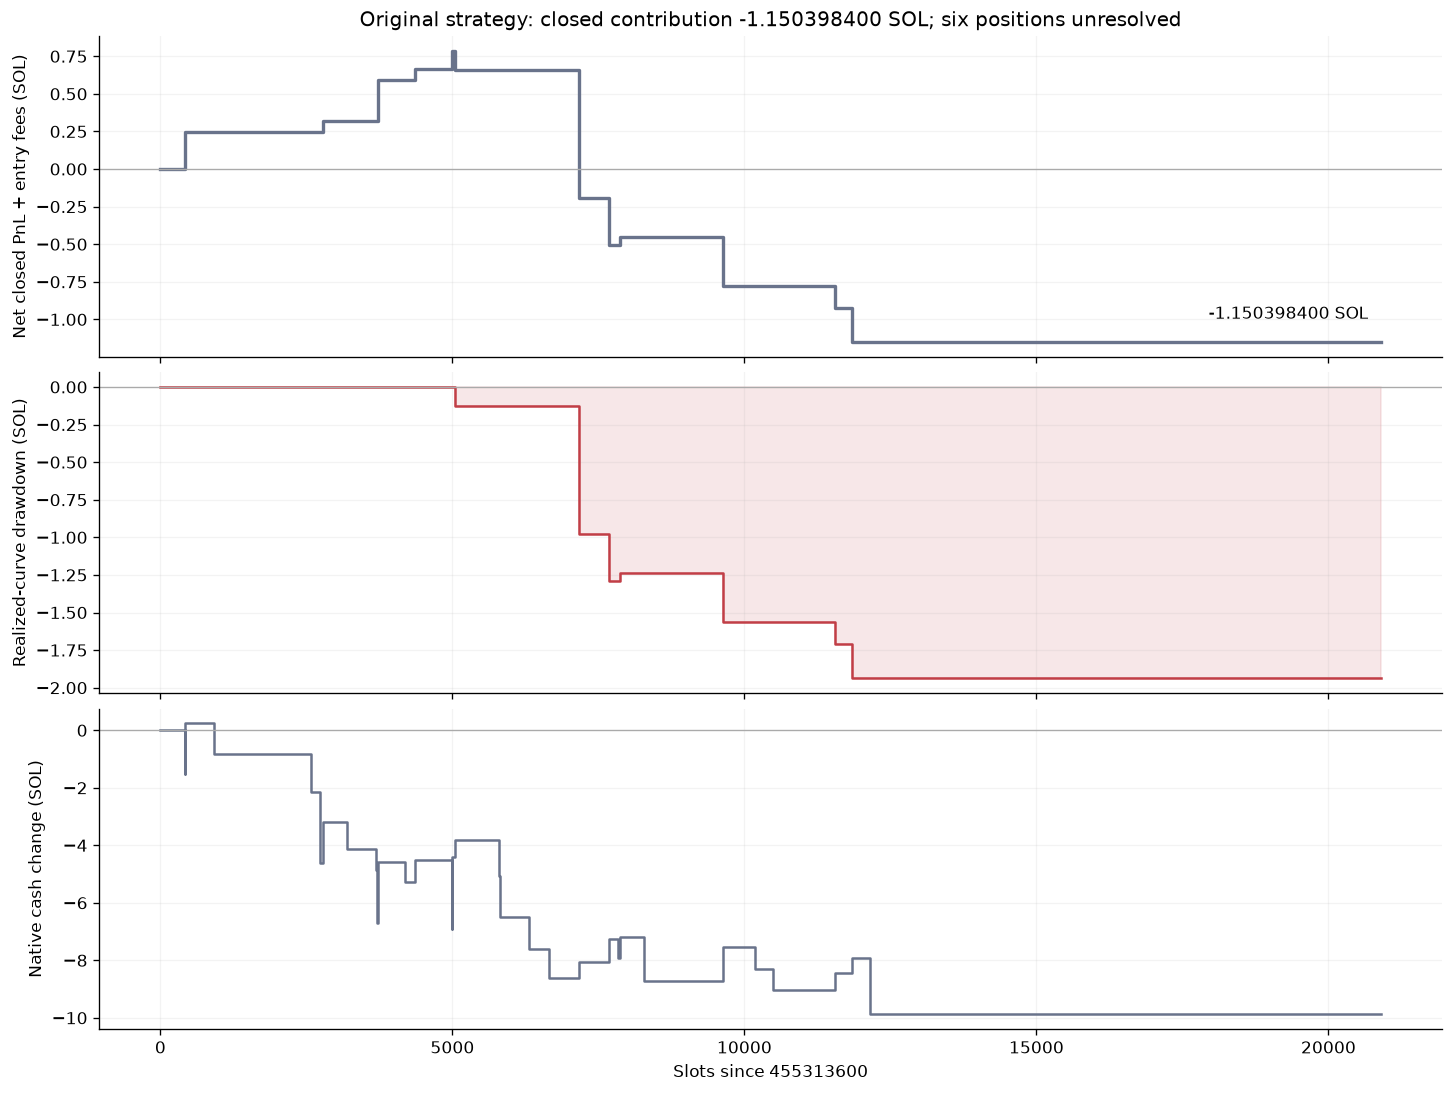

,token,slot,utc,event,pnl_SOL,cumulative_pnl_SOL
0,NEZARA,455314026,2026-10-10T16:01:33+00:00,Position closed,0.246999,0.246999
1,p-,455316088,2026-10-10T16:09:09+00:00,Failed entry fee,-0.000105,0.246894
2,VYRNO,455316387,2026-10-10T16:10:14+00:00,Position closed,0.074792,0.321686
4,DOG,455317328,2026-10-10T16:13:42+00:00,Position closed,0.268833,0.590518
5,PKMON,455317959,2026-10-10T16:16:00+00:00,Position closed,0.076934,0.667453
6,CATS,455318589,2026-10-10T16:18:19+00:00,Position closed,0.119166,0.786619
3,BRIMHUB,455318652,2026-10-10T16:18:33+00:00,Position closed,-0.129694,0.656925
7,Qweb,455320771,2026-10-10T16:26:19+00:00,Position closed,-0.849179,-0.192254
8,KUSO,455321280,2026-10-10T16:28:10+00:00,Position closed,-0.312214,-0.504468
9,QCHESHIRE,455321469,2026-10-10T16:28:51+00:00,Position closed,0.051845,-0.452623


In [4]:
events=EVENTS[RUN]
start,end=min(CLOCKS['development']),max(CLOCKS['development'])
x=np.r_[0,events['slot']-start,end-start]
y=np.r_[0,events['pnl_lamports'].cumsum()/LAMPORTS,events['pnl_lamports'].sum()/LAMPORTS]
fig,axes=plt.subplots(3,1,figsize=(12,9),sharex=True,layout='constrained')
axes[0].step(x,y,where='post',color=COLORS['before'],linewidth=2)
axes[0].set_title('Original strategy: closed contribution -1.150398400 SOL; six positions unresolved')
axes[0].set_ylabel('Net closed PnL + entry fees (SOL)')
axes[0].annotate(f'{y[-1]:+.9f} SOL',(x[-1],y[-1]),xytext=(-8,14),textcoords='offset points',ha='right')
drawdown=y-np.maximum.accumulate(y)
axes[1].step(x,drawdown,where='post',color=BAD)
axes[1].fill_between(x,drawdown,0,step='post',color=BAD,alpha=.12)
axes[1].set_ylabel('Realized-curve drawdown (SOL)')
cash=LEDGERS[RUN]
cash=cash[cash['cash_delta_lamports']!=0]
axes[2].step([0,*(cash['slot']-start),end-start],
             [0,*(cash['cash_delta_lamports'].cumsum()/LAMPORTS),cash['cash_delta_lamports'].sum()/LAMPORTS],
             where='post',color=COLORS['before'])
axes[2].set_ylabel('Native cash change (SOL)')
axes[2].set_xlabel(f'Slots since {start}')
for ax in axes:
    ax.axhline(0,color='#aaaaaa',linewidth=.8)
    ax.grid(alpha=.15)
finish_plot(fig,'original-first-hour-pnl-and-cash.png')
display(events[['token','slot','utc','event','pnl_SOL','cumulative_pnl_SOL']])

## Every original selected token

All 38 signals remain in chronological order, with GMGN links. Open positions
have an unavailable final PnL rather than zero. Risk rejections have no filled
buy and their recorded cost is shown separately from completed trades.

In [5]:
ENTRY_EXIT,FILL_MARKERS=entry_exit_records(RUN)
assert len(ENTRY_EXIT)==38 and len(FILL_MARKERS)==30
assert (FILL_MARKERS['side']=='BUY').sum()==18 and (FILL_MARKERS['side']=='SELL').sum()==12
entry_exit_view=['token','group','reason','signal_slot','entry_slot','entry_utc','exit_slot','exit_utc',
                 'entry_SOL','exit_receipt_SOL','net_pnl_SOL','open_cost_SOL','gmgn_url']
display(Markdown('### Entry and exit list for every original signal'))
linked_table(ENTRY_EXIT[entry_exit_view])
view=['token','outcome','reason','signal_slot','entry_slot','exit_slot','entry_SOL',
      'exit_receipt_SOL','net_pnl_SOL','open_cost_SOL','failed_execution_fees_SOL','remaining_tokens_raw','gmgn_url']
linked_table(positions[view])
buys=positions[positions['entry_SOL']>0]
assert len(buys)==18
display(Markdown('### All 18 filled buys'))
linked_table(buys[['token','outcome','signal_slot','entry_slot','exit_slot','entry_SOL',
                   'net_pnl_SOL','open_cost_SOL','holding_seconds','gmgn_url']])

### Entry and exit list for every original signal

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,gmgn_url
NEZARA,Profitable,TARGET,455314019,455314020,2026-10-10T16:01:32+00:00,455314026,2026-10-10T16:01:33+00:00,1.515875680,1.762874808,0.246999128,0.000000000,GMGN
henry,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455314523,455314524,2026-10-10T16:03:23+00:00,,,1.056564320,—,—,1.056564320,GMGN
p-,Entry failed,MINIMUM_OUTPUT_NOT_MET,455316087,,,,,0.000000000,—,-0.000105000,0.000000000,GMGN
VYRNO,Profitable,TARGET,455316172,455316173,2026-10-10T16:09:27+00:00,455316387,2026-10-10T16:10:14+00:00,1.341706280,1.416497914,0.074791634,0.000000000,GMGN
Snoopy,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316333,455316334,2026-10-10T16:10:02+00:00,,,2.465210856,—,—,2.465210856,GMGN
DDAVE,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316796,455316797,2026-10-10T16:11:46+00:00,,,0.937811180,—,—,0.937811180,GMGN
BRIMHUB,Unprofitable,TIMEOUT,455317286,455317287,2026-10-10T16:13:33+00:00,455318652,2026-10-10T16:18:33+00:00,0.728648094,0.598954546,-0.129693548,0.000000000,GMGN
DOG,Profitable,TARGET,455317311,455317312,2026-10-10T16:13:39+00:00,455317328,2026-10-10T16:13:42+00:00,1.823553338,2.092386051,0.268832713,0.000000000,GMGN
PKMON,Profitable,TARGET,455317791,455317792,2026-10-10T16:15:23+00:00,455317959,2026-10-10T16:16:00+00:00,0.675999373,0.752933628,0.076934255,0.000000000,GMGN
CATS,Profitable,TARGET,455318585,455318586,2026-10-10T16:18:18+00:00,455318589,2026-10-10T16:18:19+00:00,2.381423333,2.500589282,0.119165949,0.000000000,GMGN


token,outcome,reason,signal_slot,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,remaining_tokens_raw,gmgn_url
NEZARA,Profitable,TARGET,455314019,"455,314,020.000000000","455,314,026.000000000",1.515875680,1.762874808,0.246999128,0.000000000,0.000000000,0,GMGN
henry,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455314523,"455,314,524.000000000",—,1.056564320,—,—,1.056564320,0.000000000,11763264605813,GMGN
p-,Entry failed,MINIMUM_OUTPUT_NOT_MET,455316087,—,—,0.000000000,—,-0.000105000,0.000000000,0.000105000,0,GMGN
VYRNO,Profitable,TARGET,455316172,"455,316,173.000000000","455,316,387.000000000",1.341706280,1.416497914,0.074791634,0.000000000,0.000000000,0,GMGN
Snoopy,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316333,"455,316,334.000000000",—,2.465210856,—,—,2.465210856,0.000000000,41872403351426,GMGN
DDAVE,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316796,"455,316,797.000000000",—,0.937811180,—,—,0.937811180,0.000000000,24785490300603,GMGN
BRIMHUB,Losing,TIMEOUT,455317286,"455,317,287.000000000","455,318,652.000000000",0.728648094,0.598954546,-0.129693548,0.000000000,0.000000000,0,GMGN
DOG,Profitable,TARGET,455317311,"455,317,312.000000000","455,317,328.000000000",1.823553338,2.092386051,0.268832713,0.000000000,0.000000000,0,GMGN
PKMON,Profitable,TARGET,455317791,"455,317,792.000000000","455,317,959.000000000",0.675999373,0.752933628,0.076934255,0.000000000,0.000000000,0,GMGN
CATS,Profitable,TARGET,455318585,"455,318,586.000000000","455,318,589.000000000",2.381423333,2.500589282,0.119165949,0.000000000,0.000000000,0,GMGN


### All 18 filled buys

token,outcome,signal_slot,entry_slot,exit_slot,entry_SOL,net_pnl_SOL,open_cost_SOL,holding_seconds,gmgn_url
NEZARA,Profitable,455314019,"455,314,020.000000000","455,314,026.000000000",1.515875680,0.246999128,0.000000000,1.000000000,GMGN
henry,Open / unresolved,455314523,"455,314,524.000000000",—,1.056564320,—,1.056564320,—,GMGN
VYRNO,Profitable,455316172,"455,316,173.000000000","455,316,387.000000000",1.341706280,0.074791634,0.000000000,47.000000000,GMGN
Snoopy,Open / unresolved,455316333,"455,316,334.000000000",—,2.465210856,—,2.465210856,—,GMGN
DDAVE,Open / unresolved,455316796,"455,316,797.000000000",—,0.937811180,—,0.937811180,—,GMGN
BRIMHUB,Losing,455317286,"455,317,287.000000000","455,318,652.000000000",0.728648094,-0.129693548,0.000000000,300.000000000,GMGN
DOG,Profitable,455317311,"455,317,312.000000000","455,317,328.000000000",1.823553338,0.268832713,0.000000000,3.000000000,GMGN
PKMON,Profitable,455317791,"455,317,792.000000000","455,317,959.000000000",0.675999373,0.076934255,0.000000000,37.000000000,GMGN
CATS,Profitable,455318585,"455,318,586.000000000","455,318,589.000000000",2.381423333,0.119165949,0.000000000,1.000000000,GMGN
UNBOX,Open / unresolved,455319401,"455,319,402.000000000",—,1.278134722,—,1.278134722,—,GMGN


## Profitable, losing, failed and open outcomes

### Profitable: 6

token,outcome,reason,signal_slot,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,remaining_tokens_raw,gmgn_url
NEZARA,Profitable,TARGET,455314019,"455,314,020.000000000","455,314,026.000000000",1.515875680,1.762874808,0.246999128,0.000000000,0.000000000,0,GMGN
VYRNO,Profitable,TARGET,455316172,"455,316,173.000000000","455,316,387.000000000",1.341706280,1.416497914,0.074791634,0.000000000,0.000000000,0,GMGN
DOG,Profitable,TARGET,455317311,"455,317,312.000000000","455,317,328.000000000",1.823553338,2.092386051,0.268832713,0.000000000,0.000000000,0,GMGN
PKMON,Profitable,TARGET,455317791,"455,317,792.000000000","455,317,959.000000000",0.675999373,0.752933628,0.076934255,0.000000000,0.000000000,0,GMGN
CATS,Profitable,TARGET,455318585,"455,318,586.000000000","455,318,589.000000000",2.381423333,2.500589282,0.119165949,0.000000000,0.000000000,0,GMGN
QCHESHIRE,Profitable,TARGET,455321426,"455,321,427.000000000","455,321,469.000000000",0.663845420,0.715690377,0.051844957,0.000000000,0.000000000,0,GMGN


### Losing: 6

token,outcome,reason,signal_slot,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,remaining_tokens_raw,gmgn_url
BRIMHUB,Losing,TIMEOUT,455317286,"455,317,287.000000000","455,318,652.000000000",0.728648094,0.598954546,-0.129693548,0.000000000,0.000000000,0,GMGN
Qweb,Losing,TIMEOUT,455319406,"455,319,407.000000000","455,320,771.000000000",1.403320640,0.554141209,-0.849179431,0.000000000,0.000000000,0,GMGN
KUSO,Losing,TIMEOUT,455319916,"455,319,917.000000000","455,321,280.000000000",1.129363900,0.817150148,-0.312213752,0.000000000,0.000000000,0,GMGN
CRD,Losing,TIMEOUT,455321879,"455,321,880.000000000","455,323,237.000000000",1.521456678,1.198221610,-0.323235068,0.000000000,0.000000000,0,GMGN
MUNA,Losing,TIMEOUT,455323776,"455,323,777.000000000","455,325,143.000000000",0.759669700,0.609935990,-0.149733710,0.000000000,0.000000000,0,GMGN
QUANTARENA,Losing,TIMEOUT,455324088,"455,324,089.000000000","455,325,449.000000000",0.752845459,0.528248932,-0.224596527,0.000000000,0.000000000,0,GMGN


### Entry failed: 3

...

### Entry rejected: 17

token,outcome,reason,signal_slot,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,remaining_tokens_raw,gmgn_url
PAYROLL,Entry rejected,RISK_REJECTED,455319609,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
ECX,Entry rejected,RISK_REJECTED,455320465,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
PAYROLL,Entry rejected,RISK_REJECTED,455322673,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
BETDRONE,Entry rejected,RISK_REJECTED,455324158,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
STOR,Entry rejected,RISK_REJECTED,455325518,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
MASCHINA,Entry rejected,RISK_REJECTED,455325537,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
PONZI,Entry rejected,RISK_REJECTED,455326046,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
DONT,Entry rejected,RISK_REJECTED,455326076,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
毒チワワ,Entry rejected,RISK_REJECTED,455326949,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN
TOGA,Entry rejected,RISK_REJECTED,455327461,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,GMGN


### Open / unresolved: 6

token,outcome,reason,signal_slot,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,remaining_tokens_raw,gmgn_url
henry,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455314523,"455,314,524.000000000",—,1.056564320,—,—,1.056564320,0.000000000,11763264605813,GMGN
Snoopy,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316333,"455,316,334.000000000",—,2.465210856,—,—,2.465210856,0.000000000,41872403351426,GMGN
DDAVE,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316796,"455,316,797.000000000",—,0.937811180,—,—,0.937811180,0.000000000,24785490300603,GMGN
UNBOX,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455319401,"455,319,402.000000000",—,1.278134722,—,—,1.278134722,0.000000000,17776824091415,GMGN
POPPOINT,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455320252,"455,320,253.000000000",—,1.014469540,—,—,1.014469540,0.000000000,25051925498788,GMGN
PRINU,Open / unresolved,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455325754,"455,325,755.000000000",—,1.979441540,—,—,1.979441540,0.000000000,42334028648828,GMGN


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


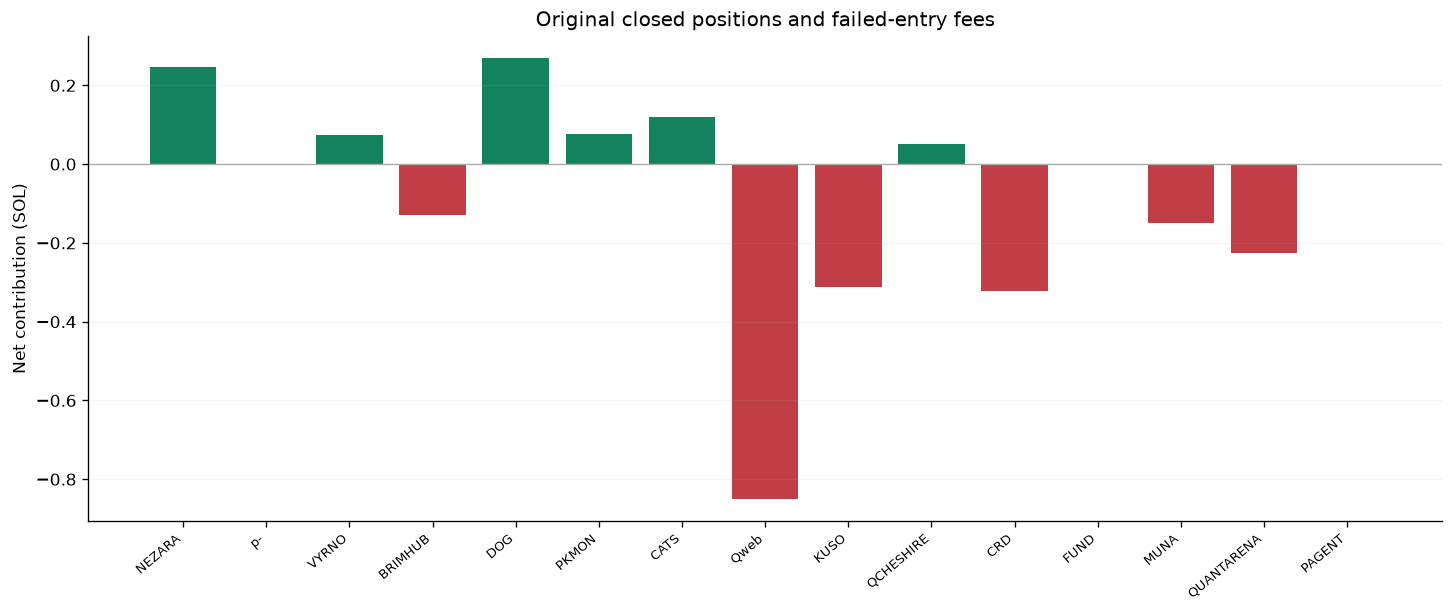

In [6]:
for outcome in ['Profitable','Losing','Entry failed','Entry rejected','Open / unresolved']:
    frame=positions[positions['outcome']==outcome]
    if len(frame):
        display(Markdown(f'### {outcome}: {len(frame)}'))
        linked_table(frame[view])
known=positions[(positions['status']=='CLOSED')|(positions['status']=='ENTRY_FAILED')]
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.bar(np.arange(len(known)),known['net_pnl_SOL'],color=[GOOD if v>0 else BAD for v in known['net_pnl_SOL']])
ax.set_xticks(np.arange(len(known)),known['token'],rotation=40,ha='right',fontsize=8)
ax.set_ylabel('Net contribution (SOL)')
ax.set_title('Original closed positions and failed-entry fees')
ax.axhline(0,color='#aaaaaa',linewidth=.8)
ax.grid(axis='y',alpha=.15)
finish_plot(fig,'original-pnl-by-token.png')

## Inspect an original position

Change `TOKEN` to a mint in the selection table and rerun this cell. The chart
shows historical price/reserve context and native position cashflow, with signal,
entry and exit slots. The native order and cash logs and signal snapshot follow.
The example is the profitable **NEZARA** position.

### NEZARA — CLOSED: TARGET

run,sample,version,token,mint,gmgn_url,outcome,status,reason,signal_slot,signal_utc,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,failed_execution_fees_SOL,open_cost_SOL,remaining_tokens_raw,holding_seconds,creator,reference_wallet
development-conditional_fraction-before,"October 10, 16:00–17:00 UTC",original,NEZARA,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,GMGN,Profitable,CLOSED,TARGET,455314019,2026-10-10T16:01:31+00:00,"455,314,020.000000000","455,314,026.000000000",1.515875680,1.762874808,0.246999128,0.000000000,0.000000000,0,1.000000000,GSReLD7g4WX7wrJw2hehNTULirCN1kk2NRDSGMAuvKGz,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH


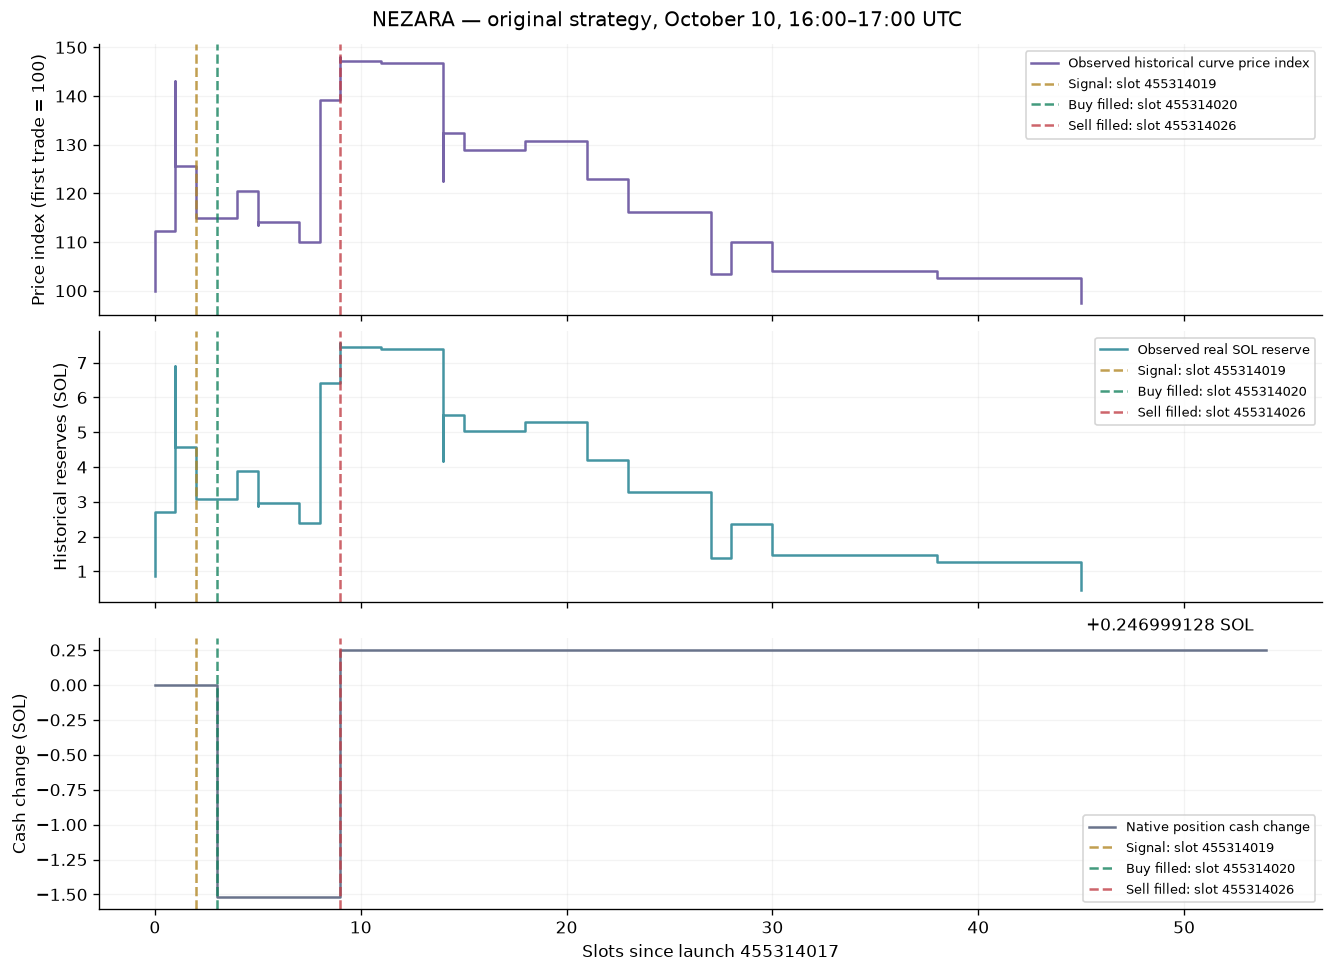

The upper two plots show historical context. The simulation has different reserves after our intervention. Cash change includes capital spent and is not marked PnL while the position is open.

#### Native order log

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason,mint,side,slot
0,1955558821015322639,1955558825310289920,00314e8bc97db972361cbbe453de869dcec198fb5a282ef5d45d5438f6a58d08,50,ORDER_ACCEPTED_AND_RESERVED,,,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,BUY,455314019
1,1955558825310289920,,00314e8bc97db972361cbbe453de869dcec198fb5a282ef5d45d5438f6a58d08,60,ORDER_FILLED_ATOMICALLY,1,,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,BUY,455314020
2,1955558846785127209,1955558851080093696,ef9e331236d43e8e79bb1693b5a5a3fec99811fd4f258267bc5f8e8290a3ba7d,50,ORDER_ACCEPTED_AND_RESERVED,,,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,SELL,455314025
3,1955558851080093696,,ef9e331236d43e8e79bb1693b5a5a3fec99811fd4f258267bc5f8e8290a3ba7d,60,ORDER_FILLED_ATOMICALLY,1,,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,SELL,455314026


#### Native cash and fee log

,slot,utc,side,reason,cash_delta_SOL,network_fee_SOL,order_id
0,455314019,2026-10-10T16:01:31+00:00,BUY,ORDER_RESERVATION,0.000000,0.000000,00314e8bc97db972361cbbe453de869dcec198fb5a282ef5d45d5438f6a58d08
1,455314020,2026-10-10T16:01:32+00:00,BUY,ORDER_SETTLEMENT,-1.515876,0.000105,00314e8bc97db972361cbbe453de869dcec198fb5a282ef5d45d5438f6a58d08
2,455314025,2026-10-10T16:01:33+00:00,SELL,ORDER_RESERVATION,0.000000,0.000000,ef9e331236d43e8e79bb1693b5a5a3fec99811fd4f258267bc5f8e8290a3ba7d
3,455314026,2026-10-10T16:01:33+00:00,SELL,ORDER_SETTLEMENT,1.762875,0.000105,ef9e331236d43e8e79bb1693b5a5a3fec99811fd4f258267bc5f8e8290a3ba7d


Signal snapshot: reference buyer cost **2.201685000 SOL**, gross buy budget **1.513731400 SOL**, our threshold **36342850841.3570579914594358237659296021984832139352847490405**, reference threshold **36343850849.5980495174604585895821760512572433382799189018326**. These are the recorded native signal features. Per-observation strategy traces were not enabled in these saved runs.

In [7]:
TOKEN='4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump'
inspect_position(RUN,TOKEN)

## Losing original position: Qweb

### Qweb — CLOSED: TIMEOUT

run,sample,version,token,mint,gmgn_url,outcome,status,reason,signal_slot,signal_utc,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,failed_execution_fees_SOL,open_cost_SOL,remaining_tokens_raw,holding_seconds,creator,reference_wallet
development-conditional_fraction-before,"October 10, 16:00–17:00 UTC",original,Qweb,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,GMGN,Losing,CLOSED,TIMEOUT,455319406,2026-10-10T16:21:19+00:00,"455,319,407.000000000","455,320,771.000000000",1.403320640,0.554141209,-0.849179431,0.000000000,0.000000000,0,300.000000000,2AgJ3bj8BrhnpuATudrn3hocEewkyMCe2B2J5Xffr3qk,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj


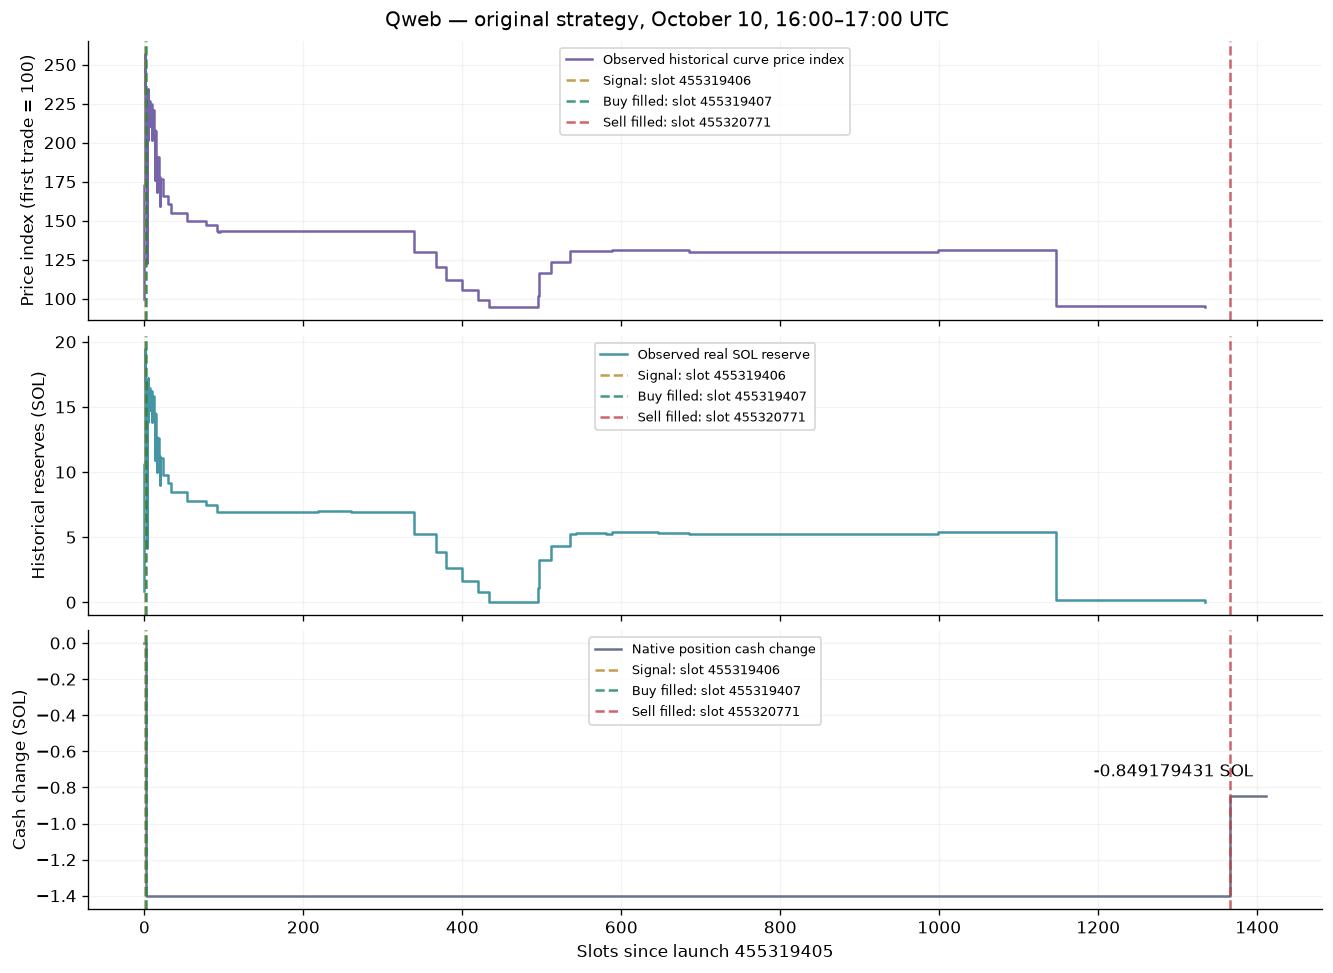

The upper two plots show historical context. The simulation has different reserves after our intervention. Cash change includes capital spent and is not marked PnL while the position is open.

#### Native order log

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason,mint,side,slot
0,1955581958004146354,1955581962299113472,166d15783f56db483c89fc1c66fe9a9a919f584d89ae22c17730ed0b4aec6e13,50,ORDER_ACCEPTED_AND_RESERVED,,,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,BUY,455319406
1,1955581962299113472,,166d15783f56db483c89fc1c66fe9a9a919f584d89ae22c17730ed0b4aec6e13,60,ORDER_FILLED_ATOMICALLY,1,,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,BUY,455319407
2,1955587816339537920,1955587820634505216,e00c244c6ef713e71c9ee94fd8226cade85f72b58a88b53ff53542a2a6ac0664,50,ORDER_ACCEPTED_AND_RESERVED,,,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,SELL,455320770
3,1955587820634505216,,e00c244c6ef713e71c9ee94fd8226cade85f72b58a88b53ff53542a2a6ac0664,60,ORDER_FILLED_ATOMICALLY,1,,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,SELL,455320771


#### Native cash and fee log

,slot,utc,side,reason,cash_delta_SOL,network_fee_SOL,order_id
34,455319406,2026-10-10T16:21:19+00:00,BUY,ORDER_RESERVATION,0.000000,0.000000,166d15783f56db483c89fc1c66fe9a9a919f584d89ae22c17730ed0b4aec6e13
35,455319407,2026-10-10T16:21:19+00:00,BUY,ORDER_SETTLEMENT,-1.403321,0.000105,166d15783f56db483c89fc1c66fe9a9a919f584d89ae22c17730ed0b4aec6e13
40,455320770,2026-10-10T16:26:19+00:00,SELL,ORDER_RESERVATION,0.000000,0.000000,e00c244c6ef713e71c9ee94fd8226cade85f72b58a88b53ff53542a2a6ac0664
41,455320771,2026-10-10T16:26:19+00:00,SELL,ORDER_SETTLEMENT,0.554141,0.000105,e00c244c6ef713e71c9ee94fd8226cade85f72b58a88b53ff53542a2a6ac0664


Signal snapshot: reference buyer cost **1.004755000 SOL**, gross buy budget **1.401176360 SOL**, our threshold **50229576630.3737534557948181702376888671483112335527794237357**, reference threshold **50230576647.0643551838059283601410572652557629144251968558376**. These are the recorded native signal features. Per-observation strategy traces were not enabled in these saved runs.

In [8]:
inspect_position(RUN,'AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump')

## Open original position: Snoopy

The conditional replay cannot certify a later historical seller's inventory.
Its unresolved context remains in the logs. Cash spent is not a confirmed
terminal loss, and no synthetic exit is invented.

### Snoopy — OPEN: CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN

run,sample,version,token,mint,gmgn_url,outcome,status,reason,signal_slot,signal_utc,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,failed_execution_fees_SOL,open_cost_SOL,remaining_tokens_raw,holding_seconds,creator,reference_wallet
development-conditional_fraction-before,"October 10, 16:00–17:00 UTC",original,Snoopy,3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,GMGN,Open / unresolved,OPEN,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316333,2026-10-10T16:10:02+00:00,"455,316,334.000000000",—,2.465210856,—,—,0.000000000,2.465210856,41872403351426,—,5rMA6GfcwVJLhnMT2tooraHYVChev7Vzu82JG4T1VYjH,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH


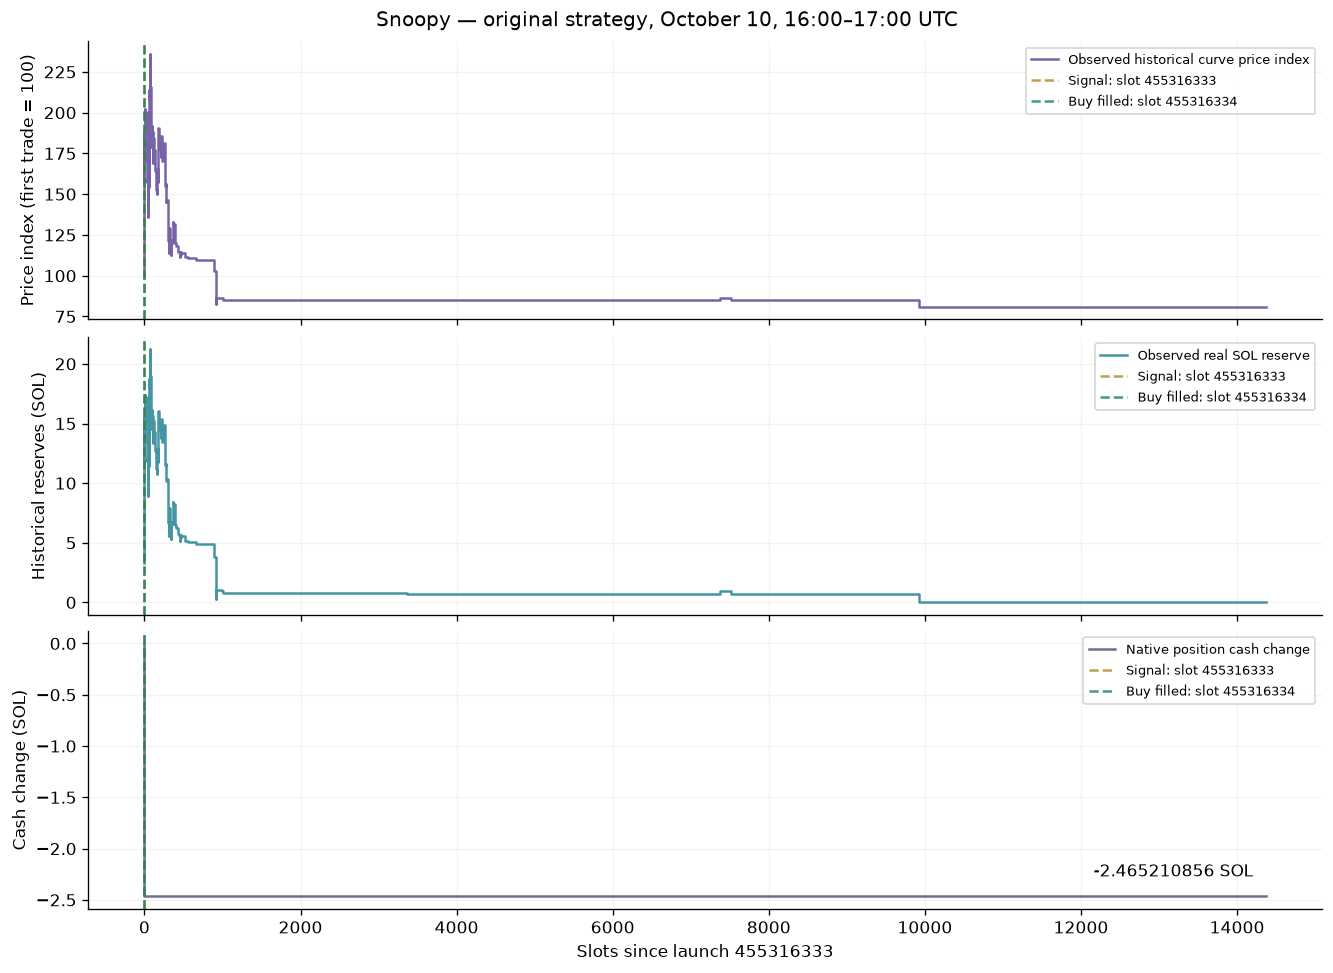

The upper two plots show historical context. The simulation has different reserves after our intervention. Cash change includes capital spent and is not marked PnL while the position is open.

#### Native order log

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason,mint,side,slot
0,1955568759569646334,1955568763864612864,76834e22dcecc0a80a2c532976b00ced2ff30d00e6abd83ae06cf1e0e5b004e5,50,ORDER_ACCEPTED_AND_RESERVED,,,3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,BUY,455316333
1,1955568763864612864,,76834e22dcecc0a80a2c532976b00ced2ff30d00e6abd83ae06cf1e0e5b004e5,60,ORDER_FILLED_ATOMICALLY,1,,3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,BUY,455316334


#### Native cash and fee log

,slot,utc,side,reason,cash_delta_SOL,network_fee_SOL,order_id
10,455316333,2026-10-10T16:10:02+00:00,BUY,ORDER_RESERVATION,0.000000,0.000000,76834e22dcecc0a80a2c532976b00ced2ff30d00e6abd83ae06cf1e0e5b004e5
11,455316334,2026-10-10T16:10:02+00:00,BUY,ORDER_SETTLEMENT,-2.465211,0.000105,76834e22dcecc0a80a2c532976b00ced2ff30d00e6abd83ae06cf1e0e5b004e5


#### Unresolved counterparty context

,mint,boundary_ordinal,reason
0,3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,1955568772454547796,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


Signal snapshot: reference buyer cost **3.015005000 SOL**, gross buy budget **2.463066576 SOL**, our threshold **46078066315.3324641505447661199366639167524337794332423388232**, reference threshold **46079066315.7894101962059008548658221765660015364758967797631**. These are the recorded native signal features. Per-observation strategy traces were not enabled in these saved runs.

In [9]:
inspect_position(RUN,'3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump')

## Failed original entry: p-

### p- — ENTRY_FAILED: MINIMUM_OUTPUT_NOT_MET

run,sample,version,token,mint,gmgn_url,outcome,status,reason,signal_slot,signal_utc,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,failed_execution_fees_SOL,open_cost_SOL,remaining_tokens_raw,holding_seconds,creator,reference_wallet
development-conditional_fraction-before,"October 10, 16:00–17:00 UTC",original,p-,Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,GMGN,Entry failed,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,455316087,2026-10-10T16:09:09+00:00,—,—,0.000000000,—,-0.000105000,0.000105000,0.000000000,0,—,4aJVUXgYcnMEwpMTyHjumrykkcqaPEuoX7sgizXpUWcC,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw


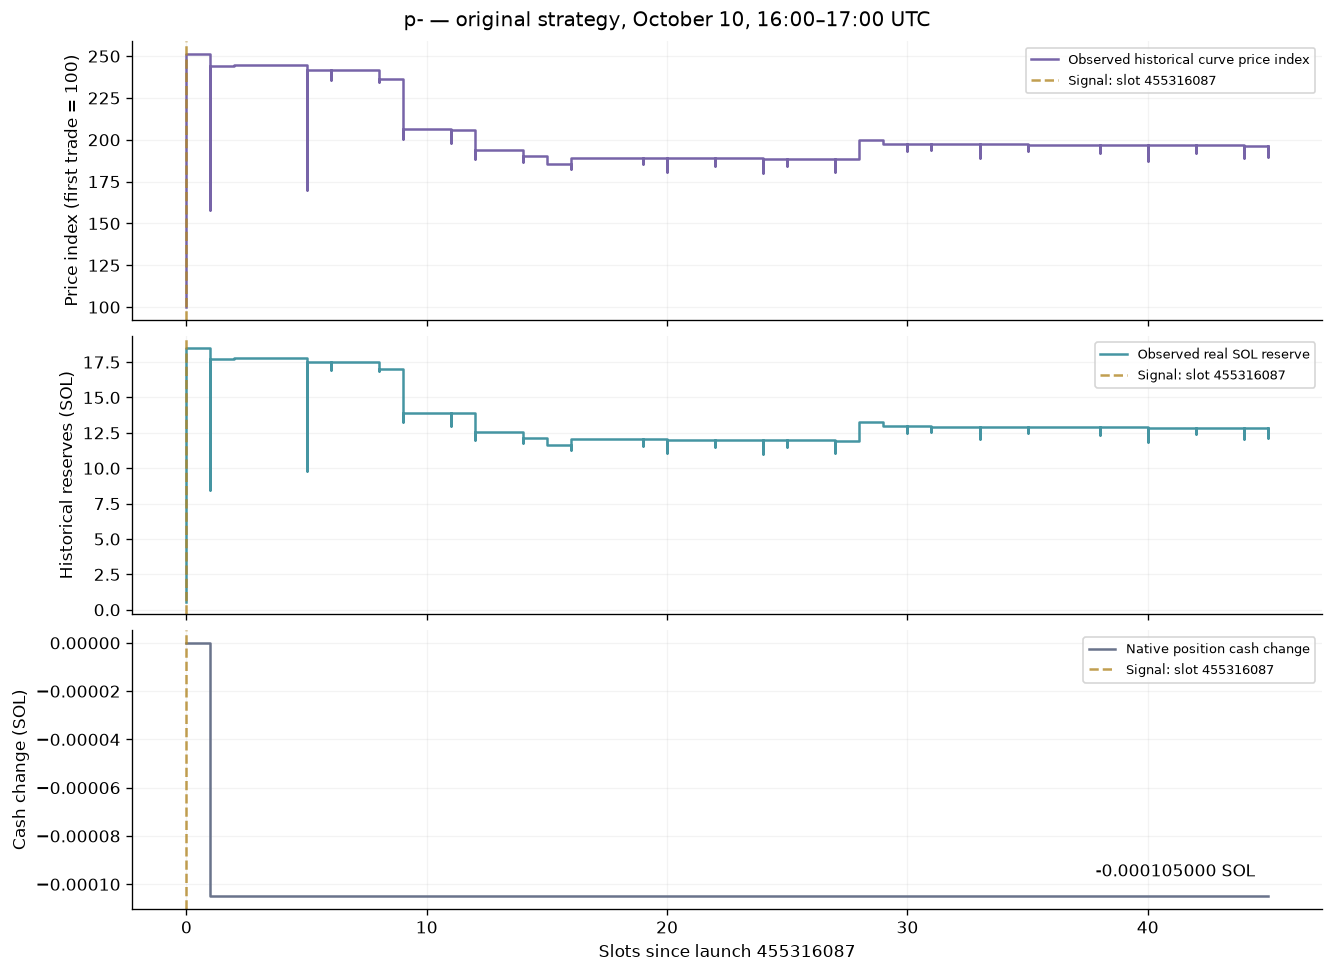

The upper two plots show historical context. The simulation has different reserves after our intervention. Cash change includes capital spent and is not marked PnL while the position is open.

#### Native order log

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason,mint,side,slot
0,1955567703007690922,1955567707302658048,9fca1a1404443a5f6b568e9934cc22ed94602bd7eee8655b8687978ed3f8b4d4,50,ORDER_ACCEPTED_AND_RESERVED,,,Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,BUY,455316087
1,1955567707302658048,,9fca1a1404443a5f6b568e9934cc22ed94602bd7eee8655b8687978ed3f8b4d4,60,ORDER_EXECUTION_FAILED_AND_RELEASED,,MINIMUM_OUTPUT_NOT_MET,Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,BUY,455316088


#### Native cash and fee log

,slot,utc,side,reason,cash_delta_SOL,network_fee_SOL,order_id
6,455316087,2026-10-10T16:09:09+00:00,BUY,ORDER_RESERVATION,0.000000,0.000000,9fca1a1404443a5f6b568e9934cc22ed94602bd7eee8655b8687978ed3f8b4d4
7,455316088,2026-10-10T16:09:09+00:00,BUY,ORDER_RELEASE,-0.000105,0.000105,9fca1a1404443a5f6b568e9934cc22ed94602bd7eee8655b8687978ed3f8b4d4


Signal snapshot: reference buyer cost **3.266786404 SOL**, gross buy budget **0.915979420 SOL**, our threshold **48392001749.2150788499704890398410401214089523581766517250982**, reference threshold **48393001760.9636954446700008959329653665680167260148225187611**. These are the recorded native signal features. Per-observation strategy traces were not enabled in these saved runs.

In [10]:
inspect_position(RUN,'Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump')

## Risk-rejected original entry: up

### up — ENTRY_REJECTED: RISK_REJECTED

run,sample,version,token,mint,gmgn_url,outcome,status,reason,signal_slot,signal_utc,entry_slot,exit_slot,entry_SOL,exit_receipt_SOL,net_pnl_SOL,failed_execution_fees_SOL,open_cost_SOL,remaining_tokens_raw,holding_seconds,creator,reference_wallet
development-conditional_fraction-before,"October 10, 16:00–17:00 UTC",original,up,2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,GMGN,Entry rejected,ENTRY_REJECTED,RISK_REJECTED,455328801,2026-10-10T16:55:34+00:00,—,—,0.000000000,—,0.000000000,0.000000000,0.000000000,0,—,DyaaFErBArgVqig8djQrvDQgii2w2A6rwxnvxwnBgrYH,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s


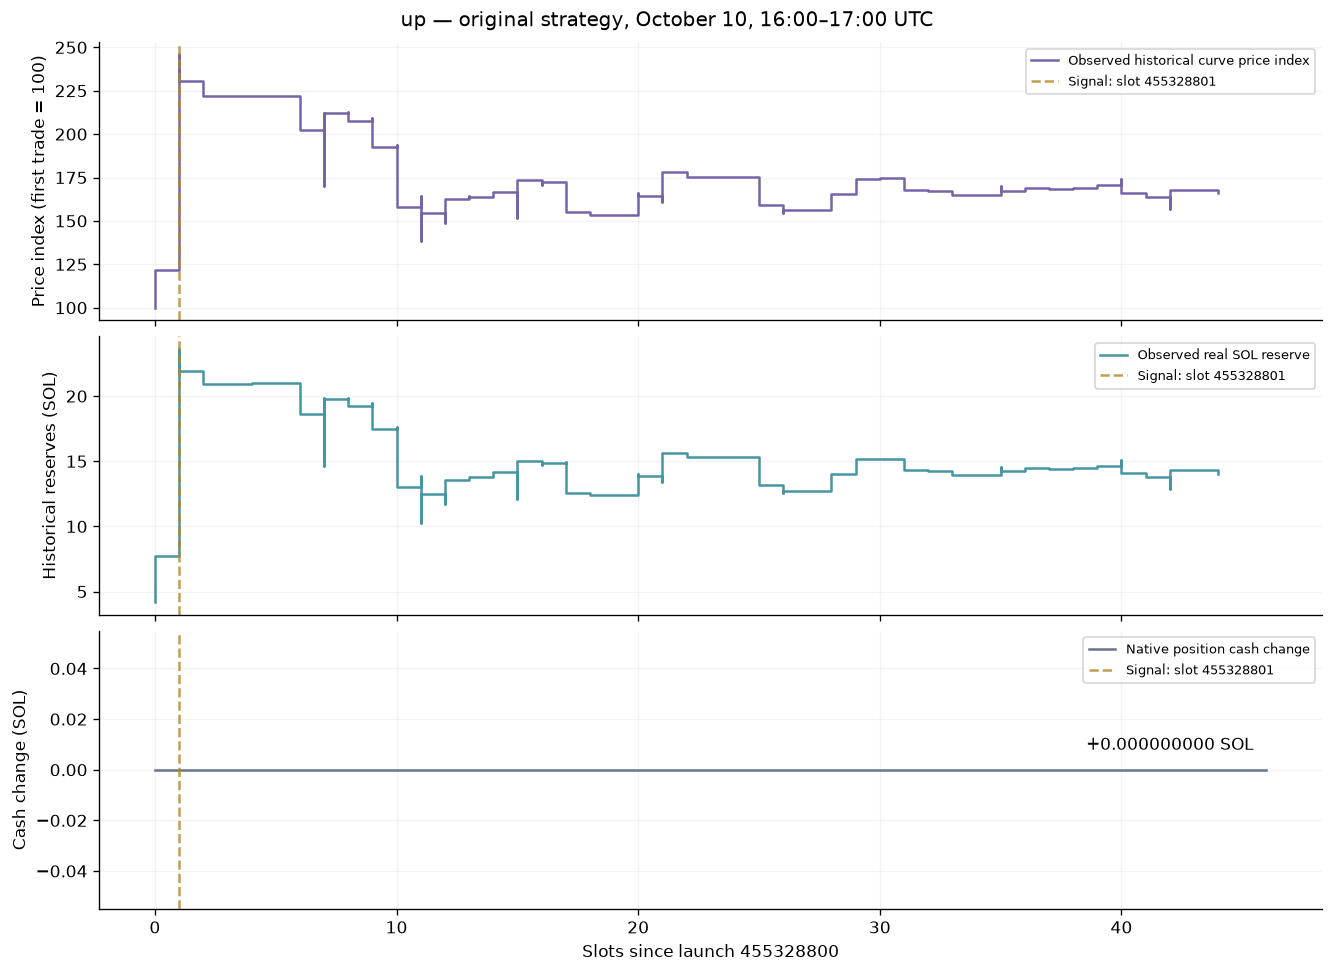

The upper two plots show historical context. The simulation has different reserves after our intervention. Cash change includes capital spent and is not marked PnL while the position is open.

#### Native order log

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason,mint,side,slot
0,1955622309221893142,,825eee13f4a6d502507ea93212f3ff196fc57d499b0c4e44a428e9d5c3f508b3,50,ORDER_REJECTED,,RISK_REJECTED,2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,BUY,455328801


#### Native cash and fee log

,slot,utc,side,reason,cash_delta_SOL,network_fee_SOL,order_id


Signal snapshot: reference buyer cost **5.200005000 SOL**, gross buy budget **1.446751900 SOL**, our threshold **55386317694.8990344351020969184519746035797022019319278694314**, reference threshold **55387317703.8599391454465183366012895013273524161517863644496**. These are the recorded native signal features. Per-observation strategy traces were not enabled in these saved runs.

In [11]:
inspect_position(RUN,'2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump')

## Every filled position, grouped by result

**Profitable**, **unprofitable** and **undecided** sections each have an entry/exit
list followed by a full chart for every position. Closed charts extend beyond
the actual sell slot, including later timeout exits. Undecided charts show all
retained price context and have a buy marker only. No exit is invented.

Green upward triangles mark native simulated **buy fills**; red downward triangles
mark native simulated **sell fills**. Their y-values are average curve execution
prices from the native ledger, normalized to the first retained historical
trade price. These exclude external fees; entry/exit cash and net PnL in the
tables include configured fees and rent. Historical observations and simulated
execution prices can differ after our reserve impact. The lower panel is
position cashflow, not marked PnL while it remains open. Longer positions also
have an inset showing the first 60 slots so the entry is easy to inspect.

## Profitable: 6 positions

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,gmgn_url
NEZARA,Profitable,TARGET,455314019,455314020,2026-10-10T16:01:32+00:00,455314026,2026-10-10T16:01:33+00:00,1.515875680,1.762874808,0.246999128,0.000000000,GMGN
VYRNO,Profitable,TARGET,455316172,455316173,2026-10-10T16:09:27+00:00,455316387,2026-10-10T16:10:14+00:00,1.341706280,1.416497914,0.074791634,0.000000000,GMGN
DOG,Profitable,TARGET,455317311,455317312,2026-10-10T16:13:39+00:00,455317328,2026-10-10T16:13:42+00:00,1.823553338,2.092386051,0.268832713,0.000000000,GMGN
PKMON,Profitable,TARGET,455317791,455317792,2026-10-10T16:15:23+00:00,455317959,2026-10-10T16:16:00+00:00,0.675999373,0.752933628,0.076934255,0.000000000,GMGN
CATS,Profitable,TARGET,455318585,455318586,2026-10-10T16:18:18+00:00,455318589,2026-10-10T16:18:19+00:00,2.381423333,2.500589282,0.119165949,0.000000000,GMGN
QCHESHIRE,Profitable,TARGET,455321426,455321427,2026-10-10T16:28:42+00:00,455321469,2026-10-10T16:28:51+00:00,0.663845420,0.715690377,0.051844957,0.000000000,GMGN


### [NEZARA](https://gmgn.ai/sol/token/4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump)

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


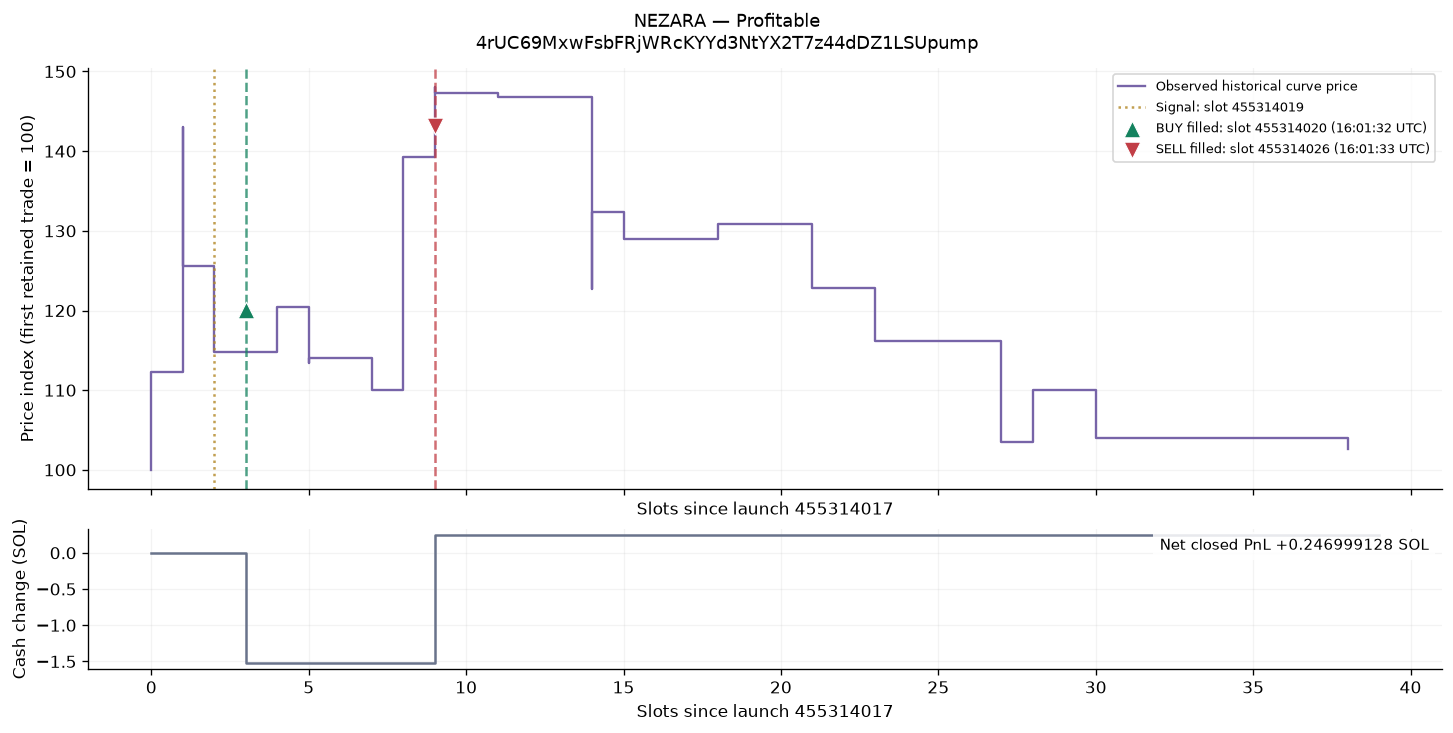

### [VYRNO](https://gmgn.ai/sol/token/7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump)

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


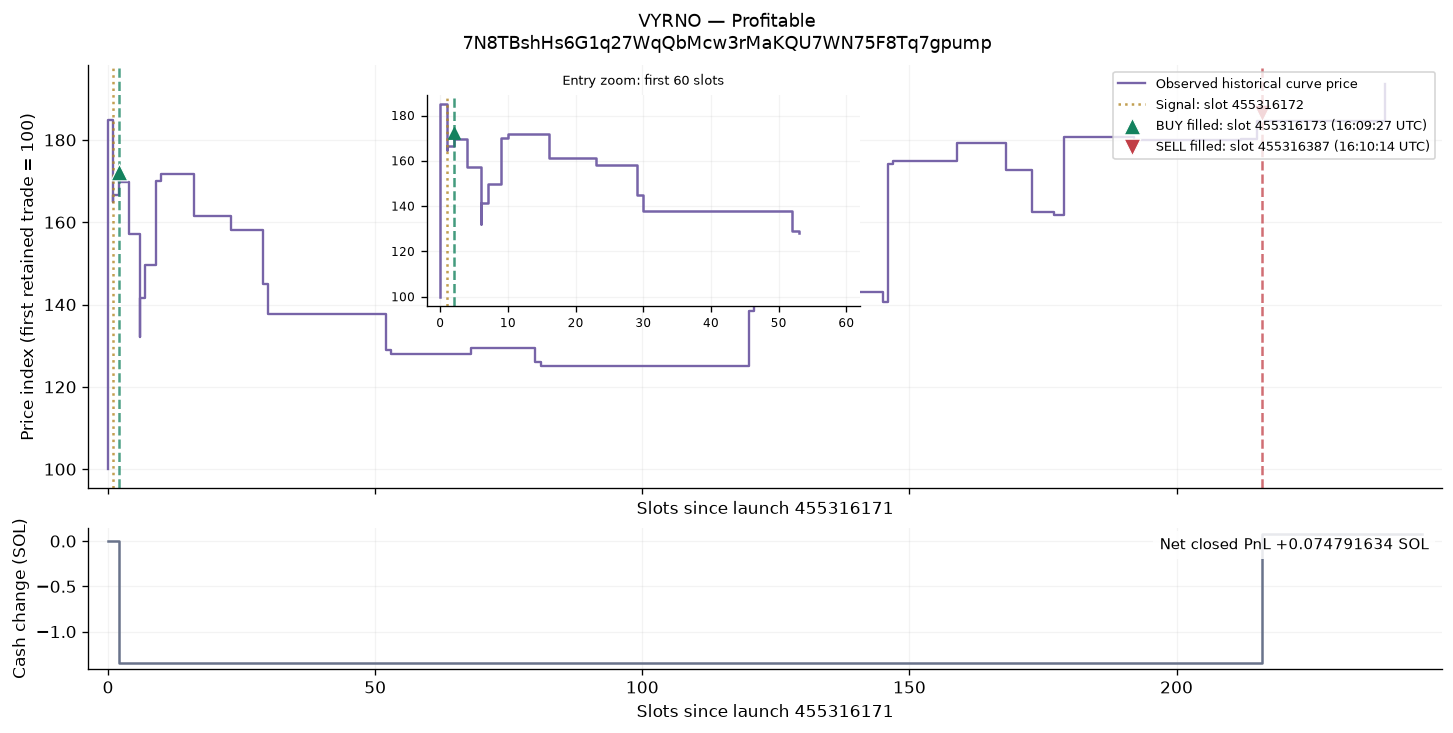

### [DOG](https://gmgn.ai/sol/token/6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump)

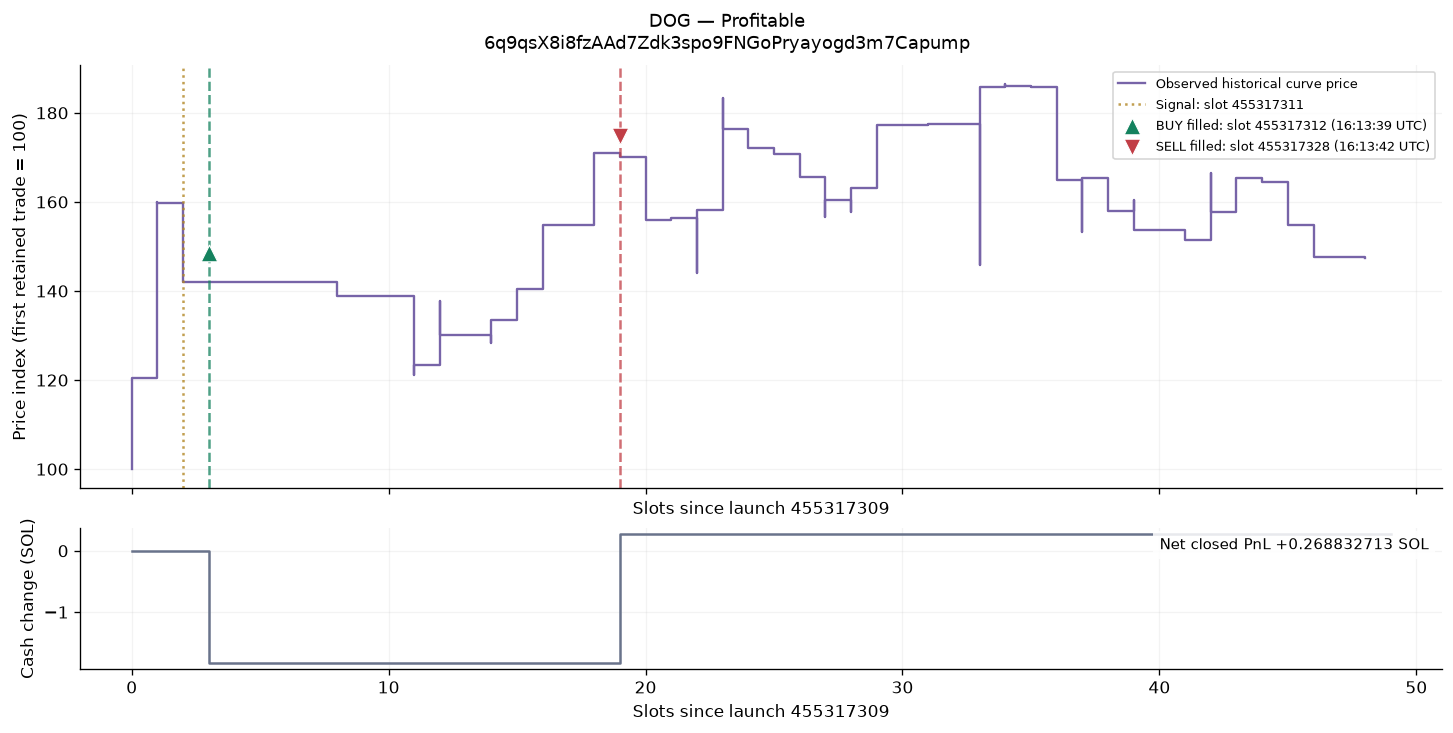

### [PKMON](https://gmgn.ai/sol/token/7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn)

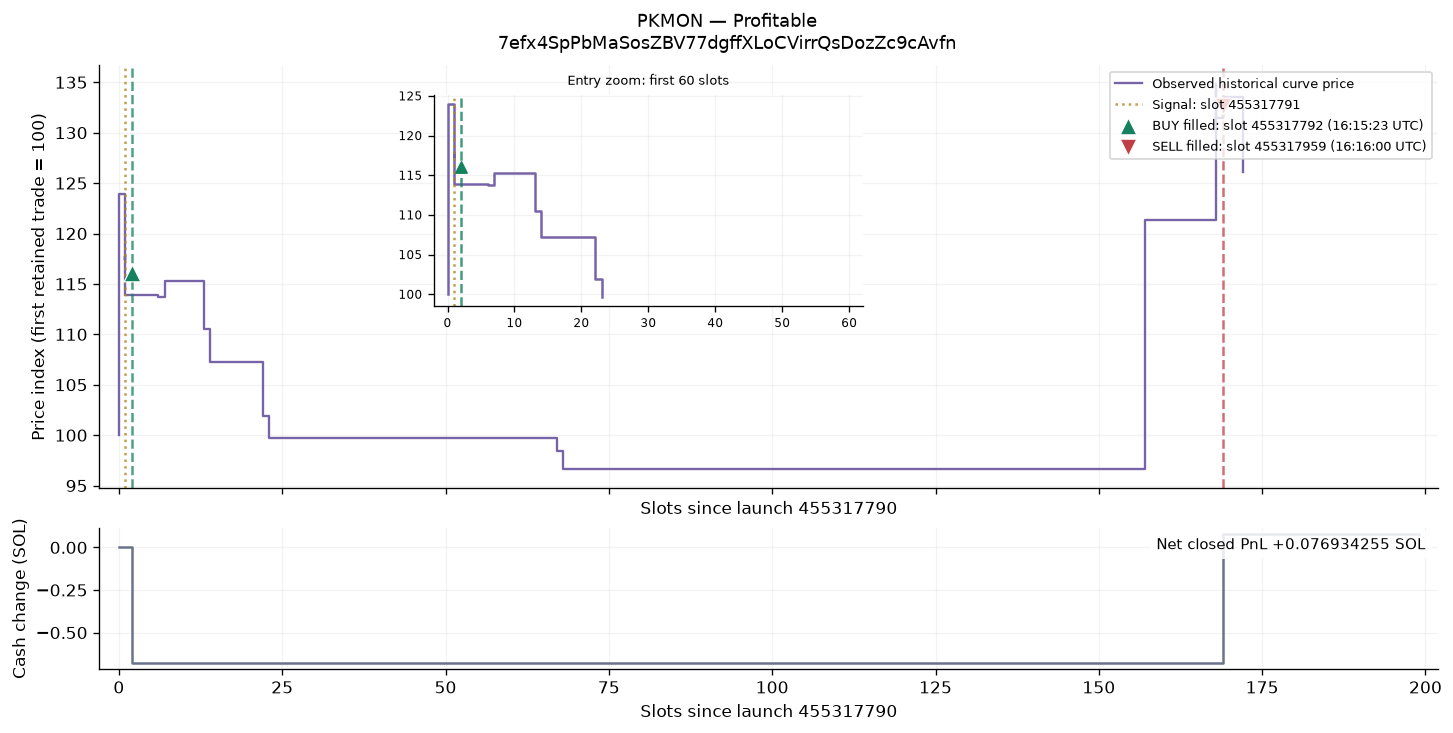

### [CATS](https://gmgn.ai/sol/token/CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump)

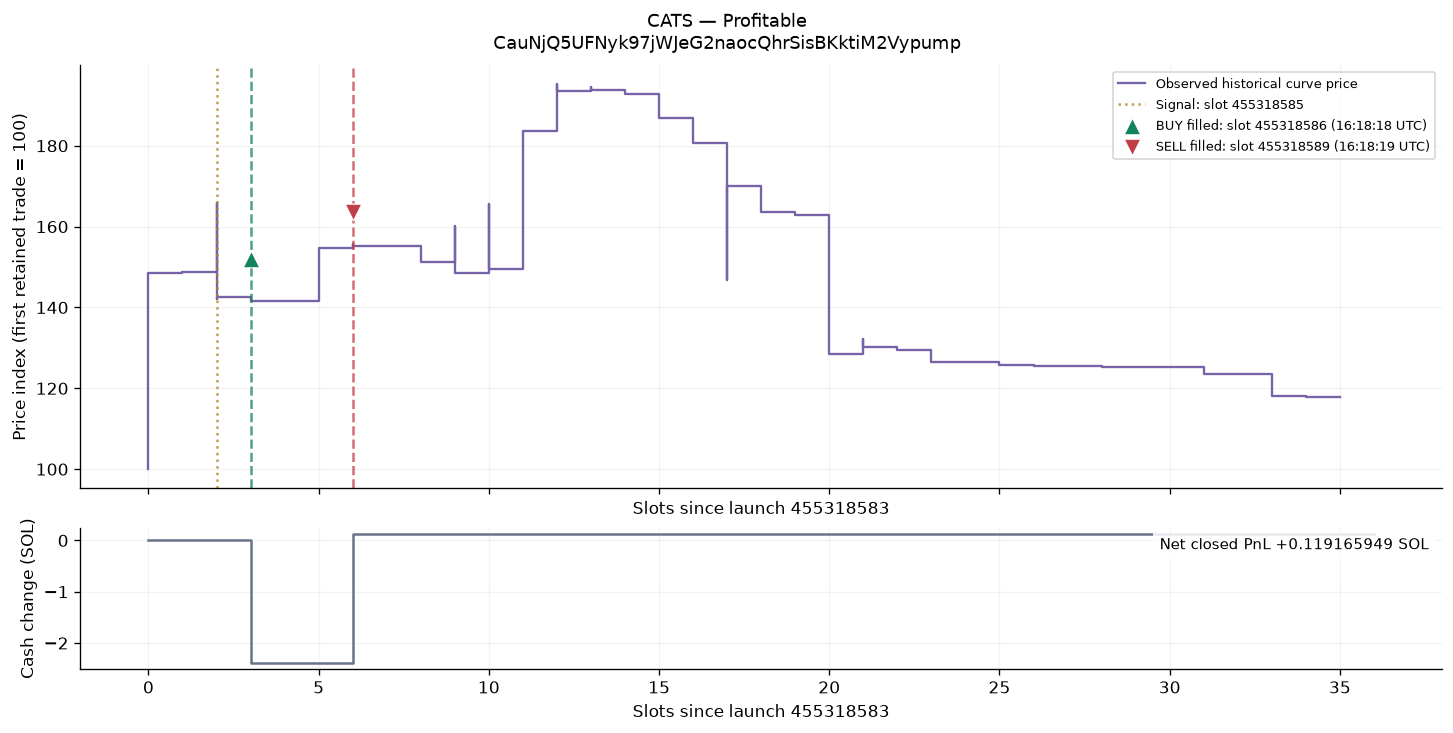

### [QCHESHIRE](https://gmgn.ai/sol/token/GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu)

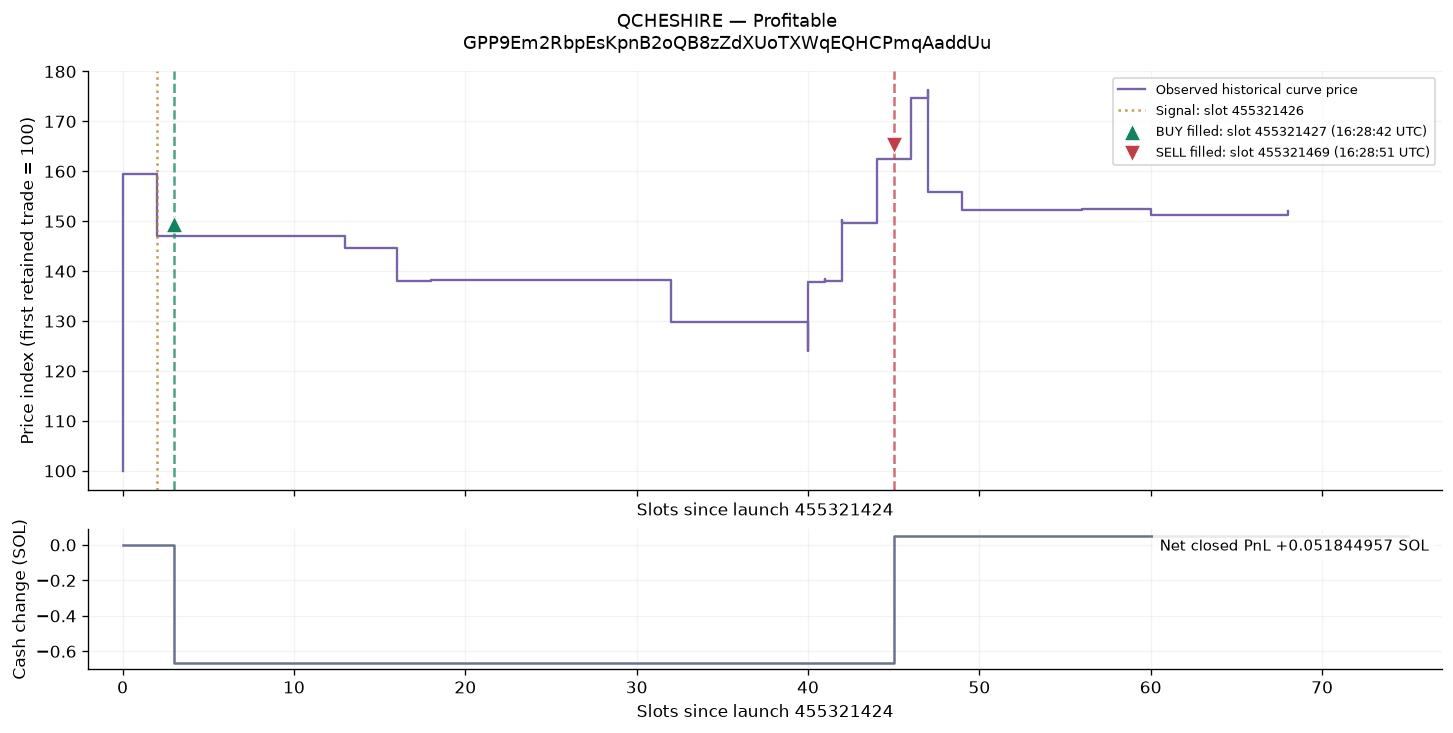

## Unprofitable: 6 positions

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,gmgn_url
BRIMHUB,Unprofitable,TIMEOUT,455317286,455317287,2026-10-10T16:13:33+00:00,455318652,2026-10-10T16:18:33+00:00,0.728648094,0.598954546,-0.129693548,0.000000000,GMGN
Qweb,Unprofitable,TIMEOUT,455319406,455319407,2026-10-10T16:21:19+00:00,455320771,2026-10-10T16:26:19+00:00,1.403320640,0.554141209,-0.849179431,0.000000000,GMGN
KUSO,Unprofitable,TIMEOUT,455319916,455319917,2026-10-10T16:23:10+00:00,455321280,2026-10-10T16:28:10+00:00,1.129363900,0.817150148,-0.312213752,0.000000000,GMGN
CRD,Unprofitable,TIMEOUT,455321879,455321880,2026-10-10T16:30:19+00:00,455323237,2026-10-10T16:35:19+00:00,1.521456678,1.198221610,-0.323235068,0.000000000,GMGN
MUNA,Unprofitable,TIMEOUT,455323776,455323777,2026-10-10T16:37:17+00:00,455325143,2026-10-10T16:42:17+00:00,0.759669700,0.609935990,-0.149733710,0.000000000,GMGN
QUANTARENA,Unprofitable,TIMEOUT,455324088,455324089,2026-10-10T16:38:24+00:00,455325449,2026-10-10T16:43:24+00:00,0.752845459,0.528248932,-0.224596527,0.000000000,GMGN


### [BRIMHUB](https://gmgn.ai/sol/token/6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump)

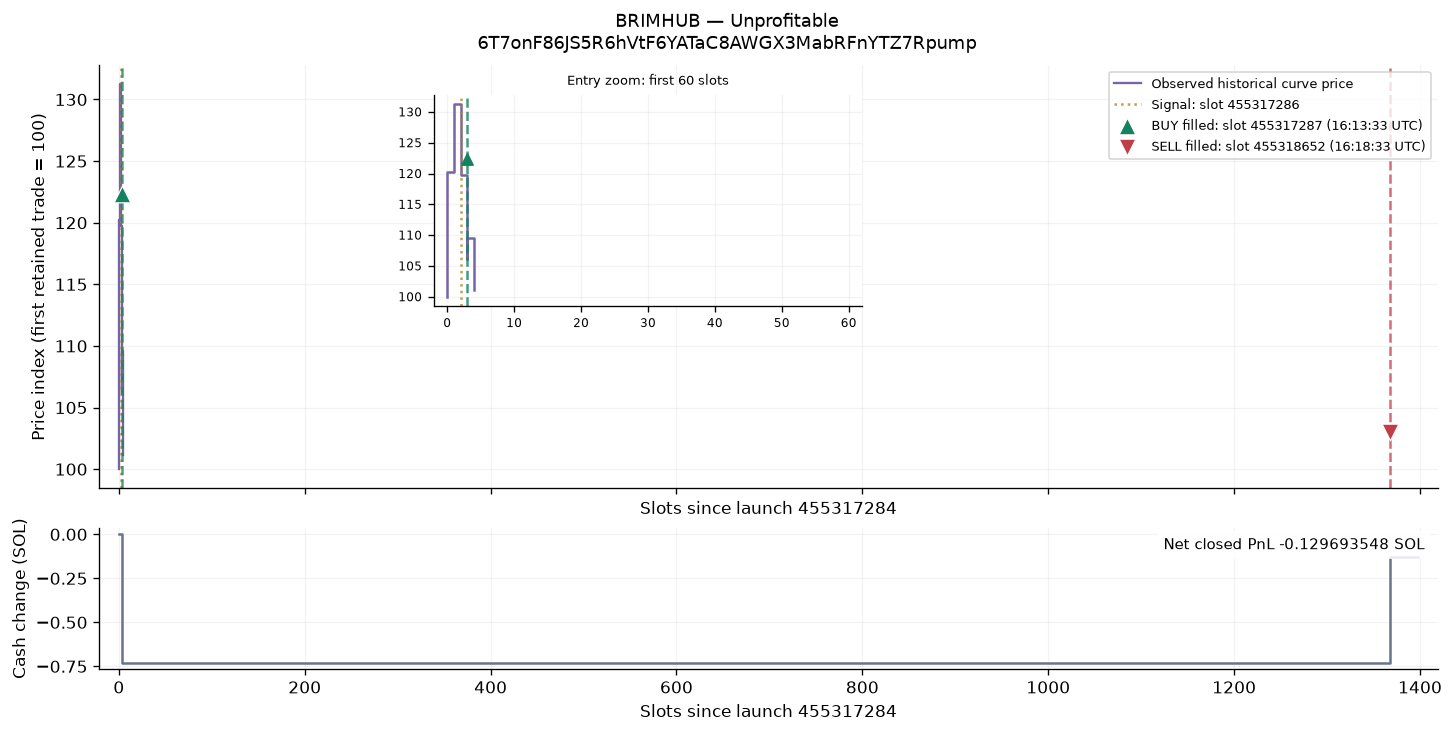

### [Qweb](https://gmgn.ai/sol/token/AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump)

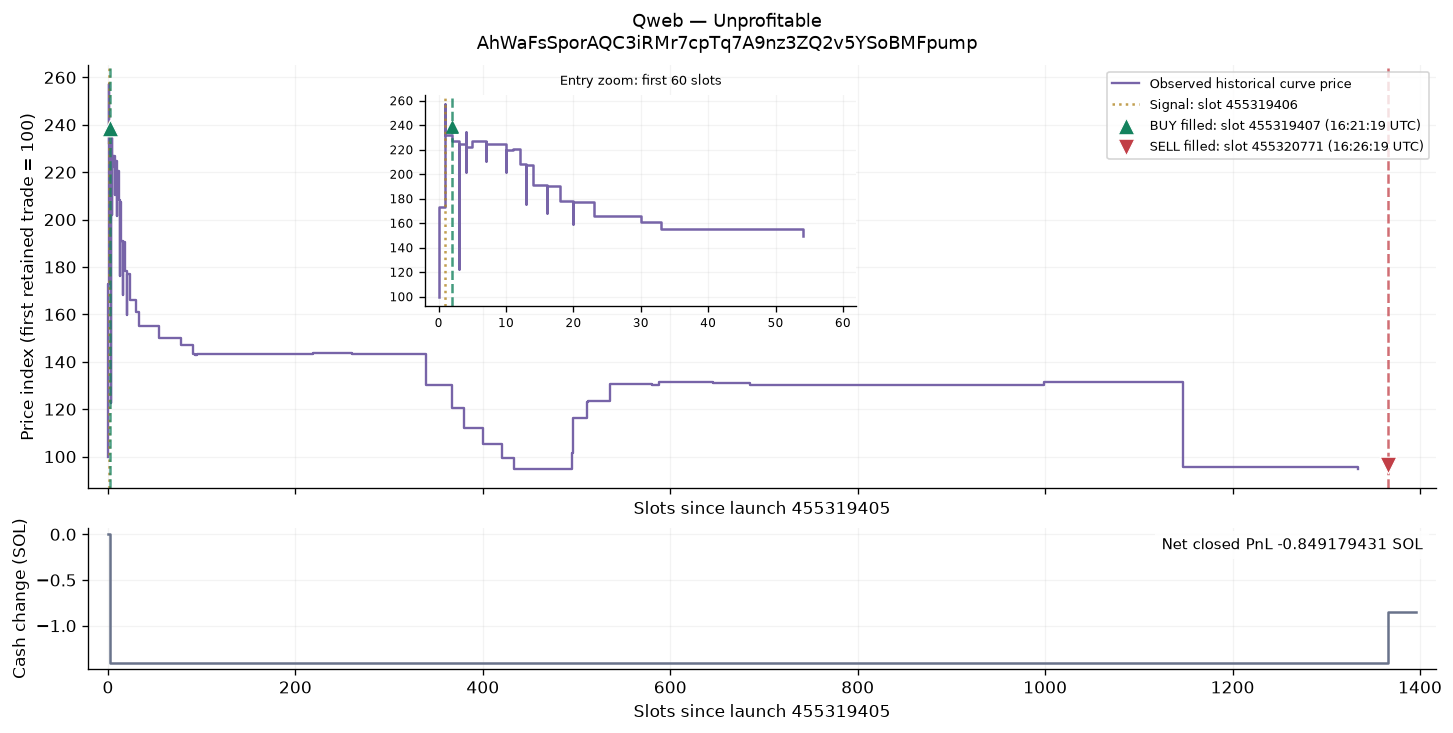

### [KUSO](https://gmgn.ai/sol/token/AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump)

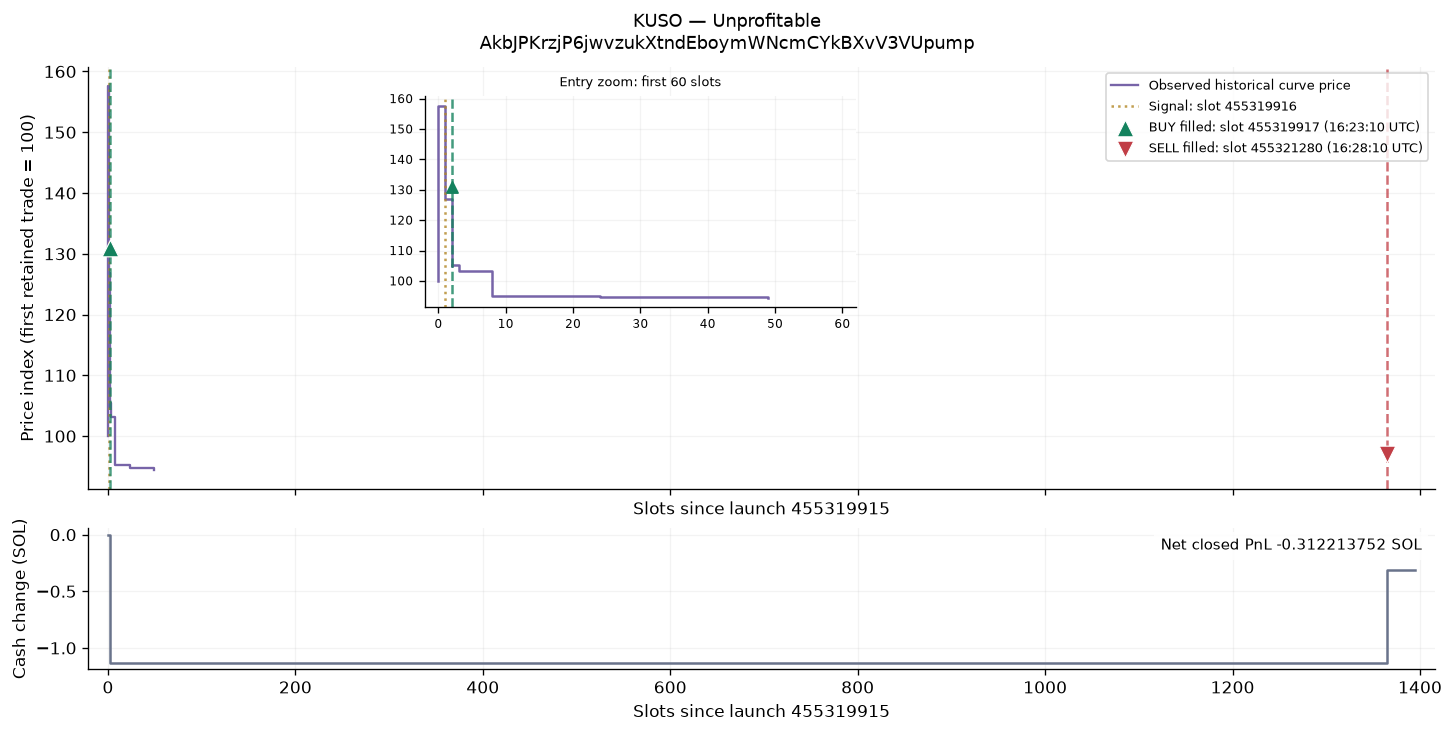

### [CRD](https://gmgn.ai/sol/token/CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump)

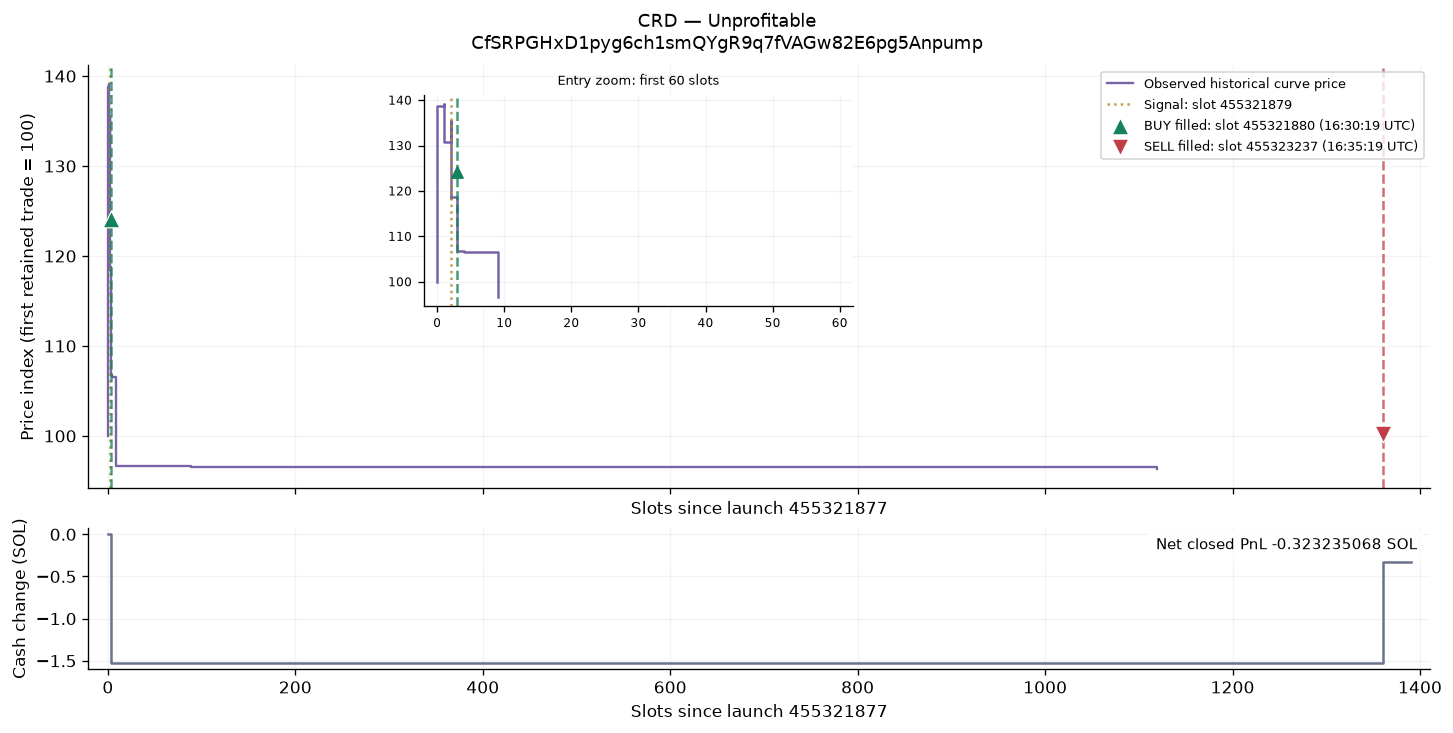

### [MUNA](https://gmgn.ai/sol/token/HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump)

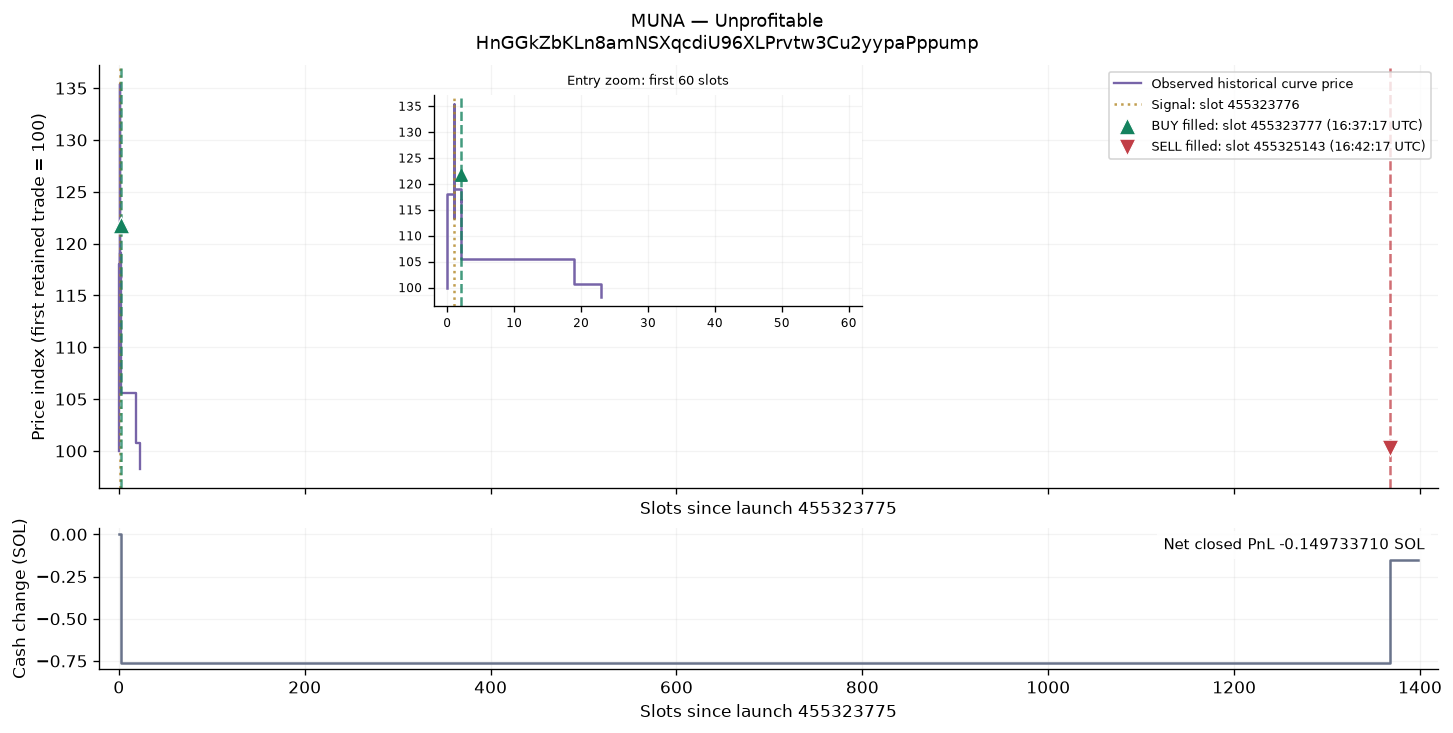

### [QUANTARENA](https://gmgn.ai/sol/token/D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump)

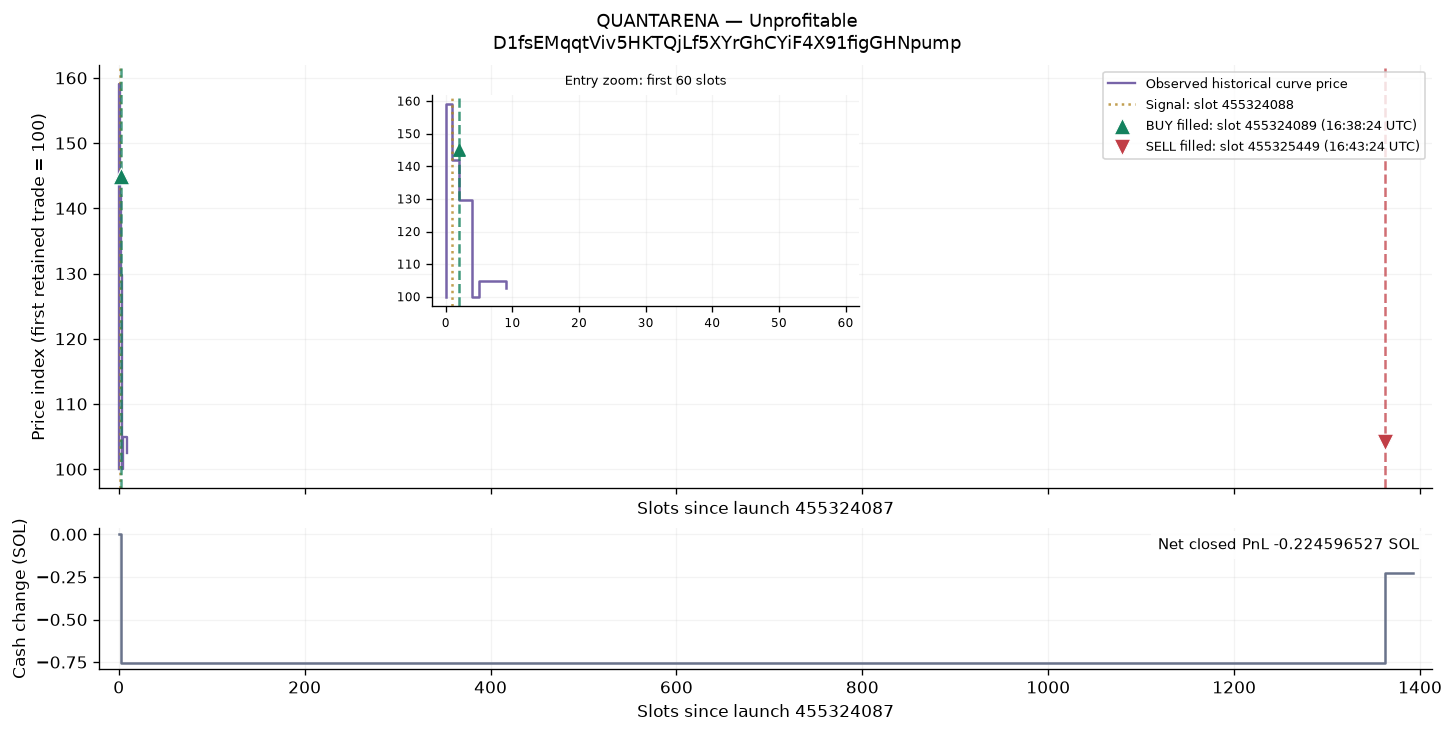

## Undecided: 6 positions

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,gmgn_url
henry,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455314523,455314524,2026-10-10T16:03:23+00:00,,,1.056564320,—,—,1.056564320,GMGN
Snoopy,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316333,455316334,2026-10-10T16:10:02+00:00,,,2.465210856,—,—,2.465210856,GMGN
DDAVE,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455316796,455316797,2026-10-10T16:11:46+00:00,,,0.937811180,—,—,0.937811180,GMGN
UNBOX,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455319401,455319402,2026-10-10T16:21:18+00:00,,,1.278134722,—,—,1.278134722,GMGN
POPPOINT,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455320252,455320253,2026-10-10T16:24:25+00:00,,,1.014469540,—,—,1.014469540,GMGN
PRINU,Undecided,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,455325754,455325755,2026-10-10T16:44:30+00:00,,,1.979441540,—,—,1.979441540,GMGN


### [henry](https://gmgn.ai/sol/token/Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump)

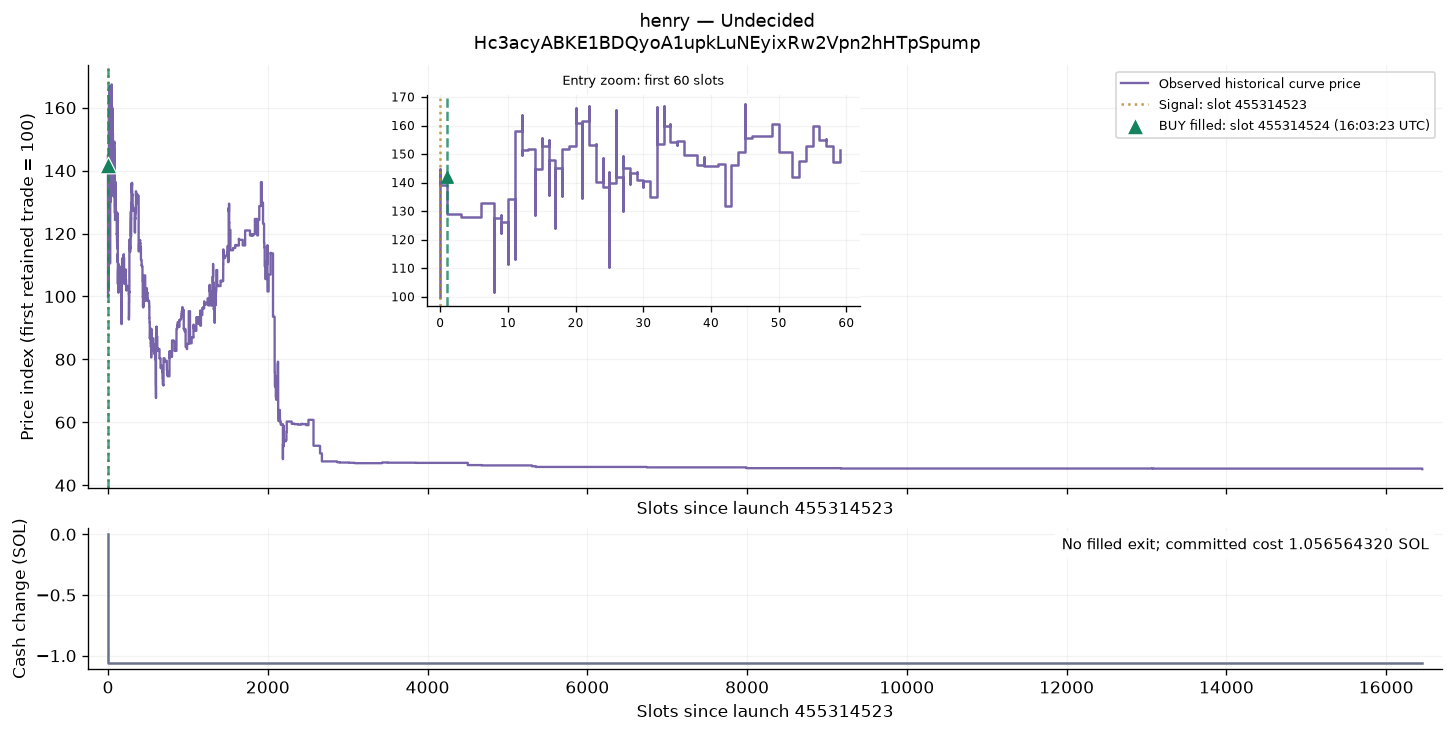

### [Snoopy](https://gmgn.ai/sol/token/3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump)

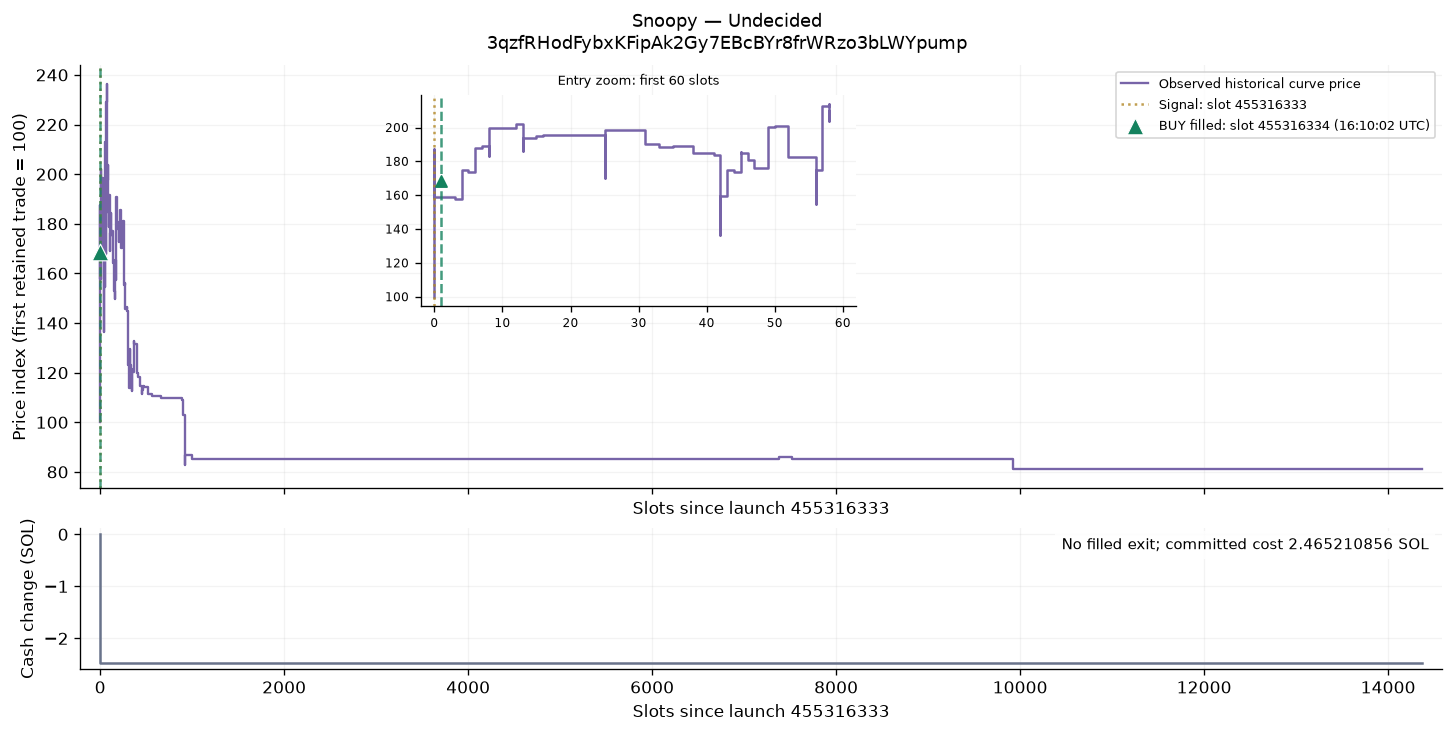

### [DDAVE](https://gmgn.ai/sol/token/FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump)

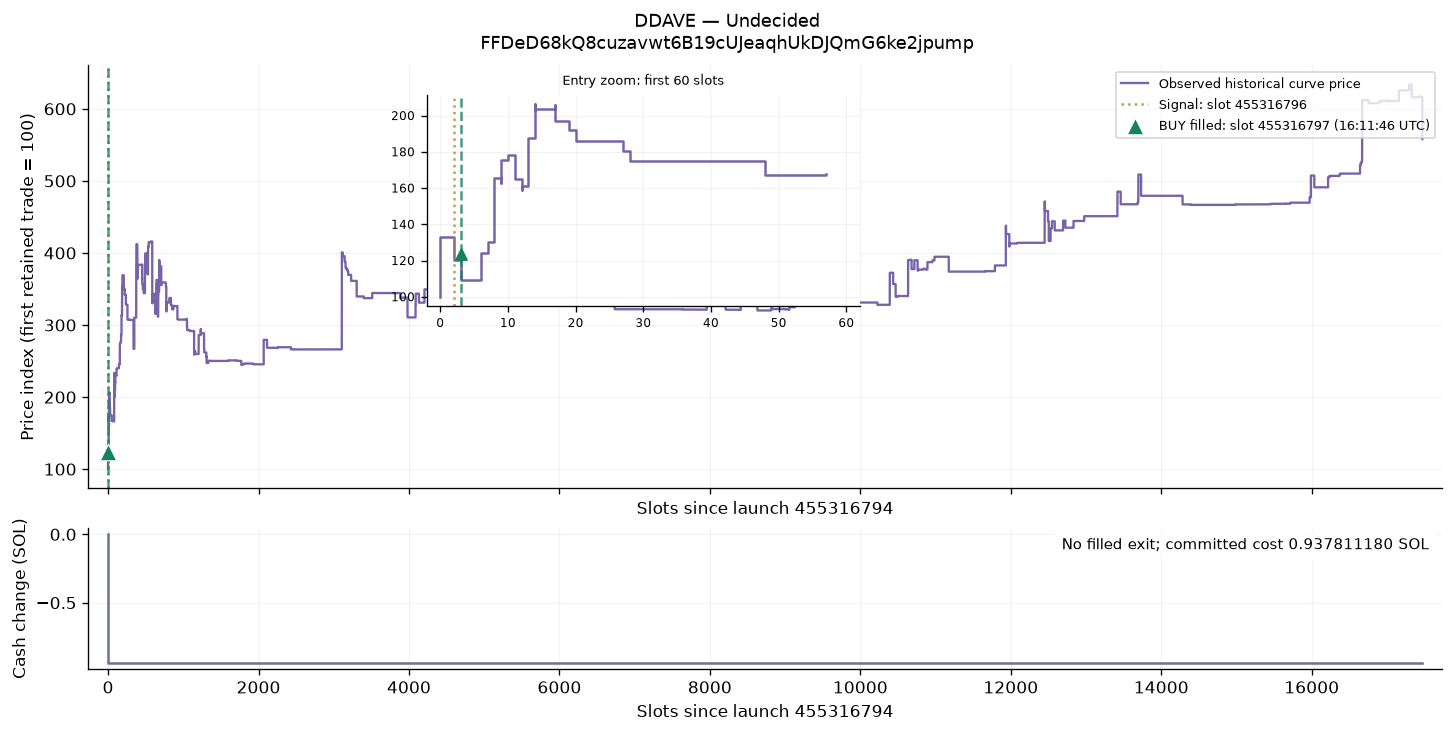

### [UNBOX](https://gmgn.ai/sol/token/9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box)

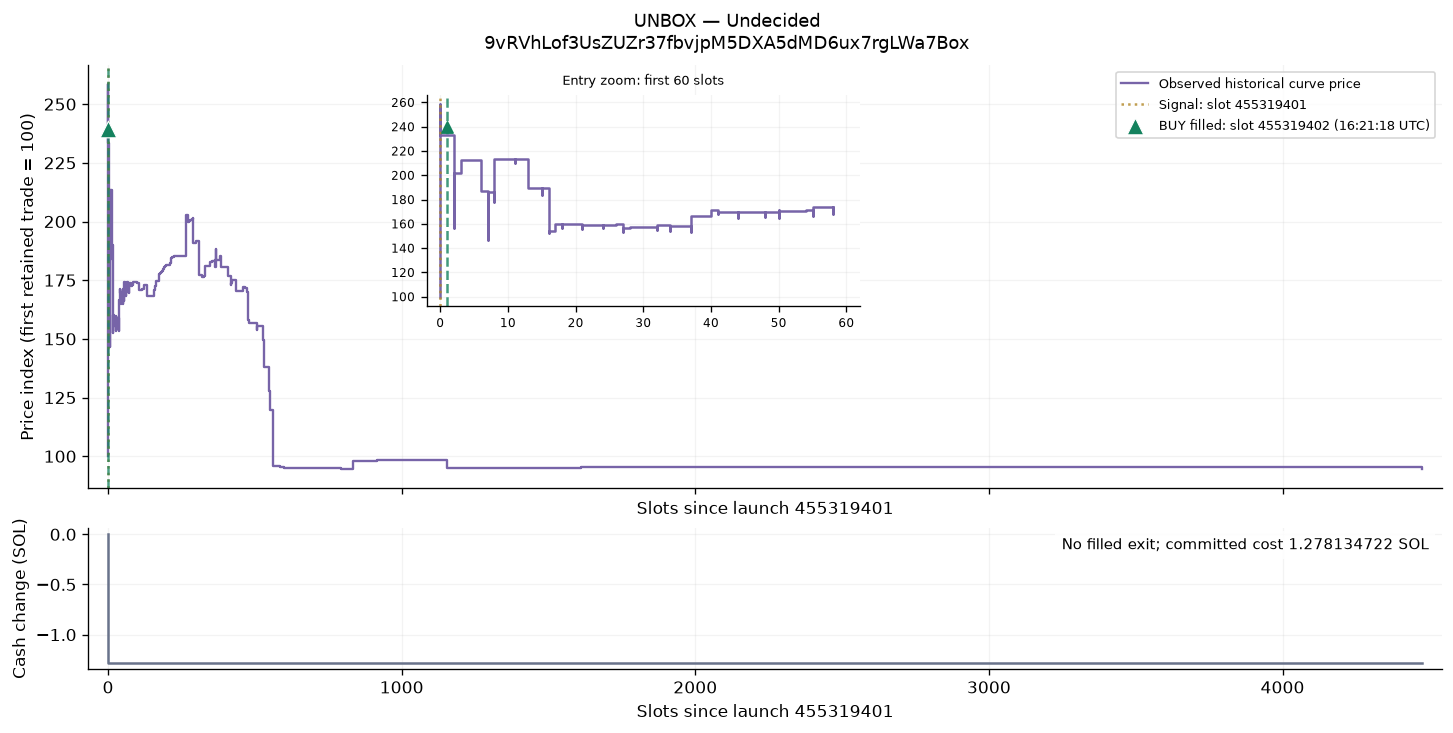

### [POPPOINT](https://gmgn.ai/sol/token/8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump)

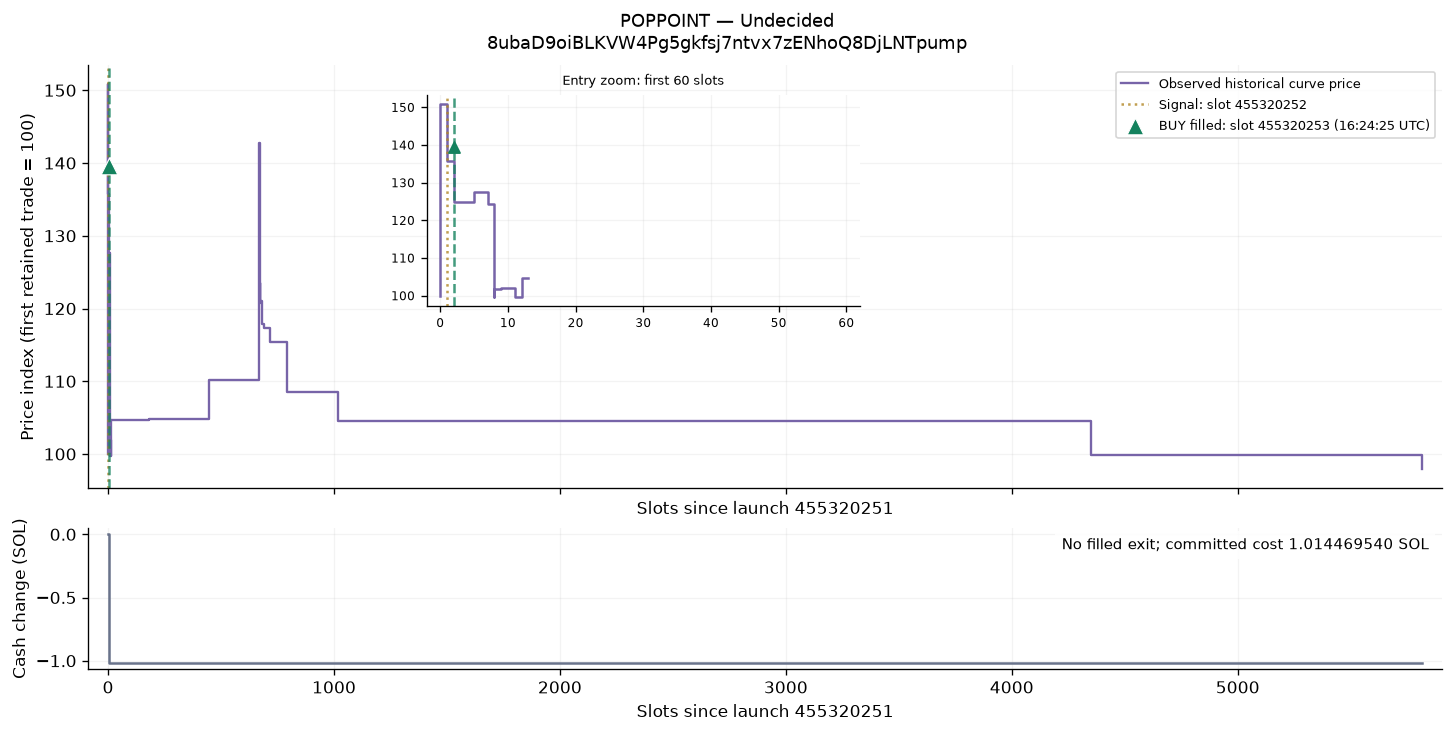

### [PRINU](https://gmgn.ai/sol/token/HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump)

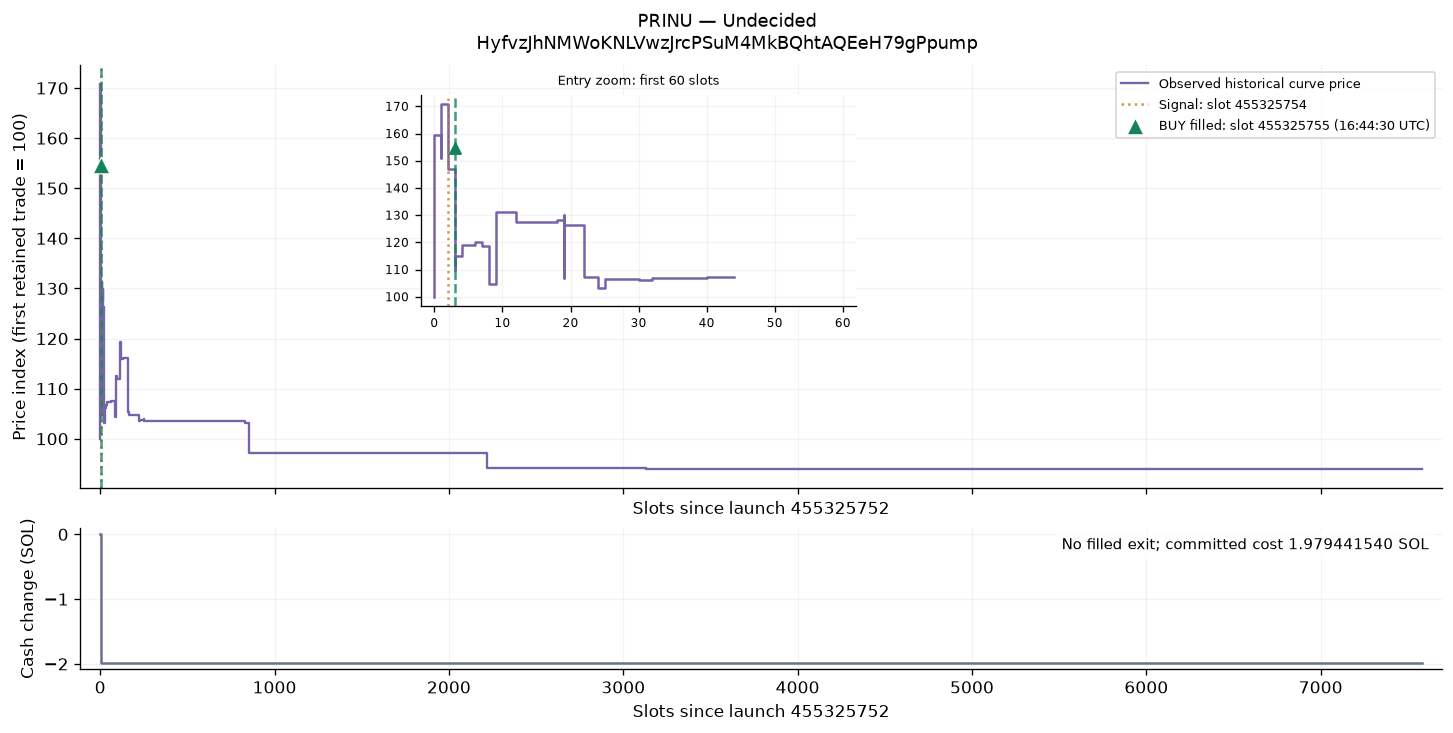

In [12]:
row_by_mint={p['mint']:p for p in RESULT['positions']}
chart_records=[]
for group in ['Profitable','Unprofitable','Undecided','Breakeven']:
    frame=ENTRY_EXIT[ENTRY_EXIT['group']==group]
    if not len(frame):continue
    display(Markdown(f'## {group}: {len(frame)} positions'))
    linked_table(frame[entry_exit_view])
    for row in frame.itertuples():
        display(Markdown(f'### [{row.token}]({row.gmgn_url})'))
        filename=position_entry_exit_chart(RUN,row.mint)
        chart_records.append(dict(mint=row.mint,token=row.token,group=group,chart=filename,
                                  entry_slot=int(row.entry_slot),exit_slot=int(row.exit_slot) if pd.notna(row.exit_slot) else None))
assert len(chart_records)==18
assert set(c['mint'] for c in chart_records)==set(buys['mint'])
assert sum(c['exit_slot'] is not None for c in chart_records)==12

## Failed and rejected entries

These orders never established a position. They have signal/attempt lines, with
no buy or sell triangles. Failed entry fees stay in the cash/PnL accounting.

## Entry failed: 3 signals

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,gmgn_url
p-,Entry failed,MINIMUM_OUTPUT_NOT_MET,455316087,,,,,0.000000000,—,-0.000105000,0.000000000,GMGN
FUND,Entry failed,MINIMUM_OUTPUT_NOT_MET,455322764,,,,,0.000000000,—,-0.000105000,0.000000000,GMGN
PAGENT,Entry failed,MINIMUM_OUTPUT_NOT_MET,455325688,,,,,0.000000000,—,-0.000105000,0.000000000,GMGN


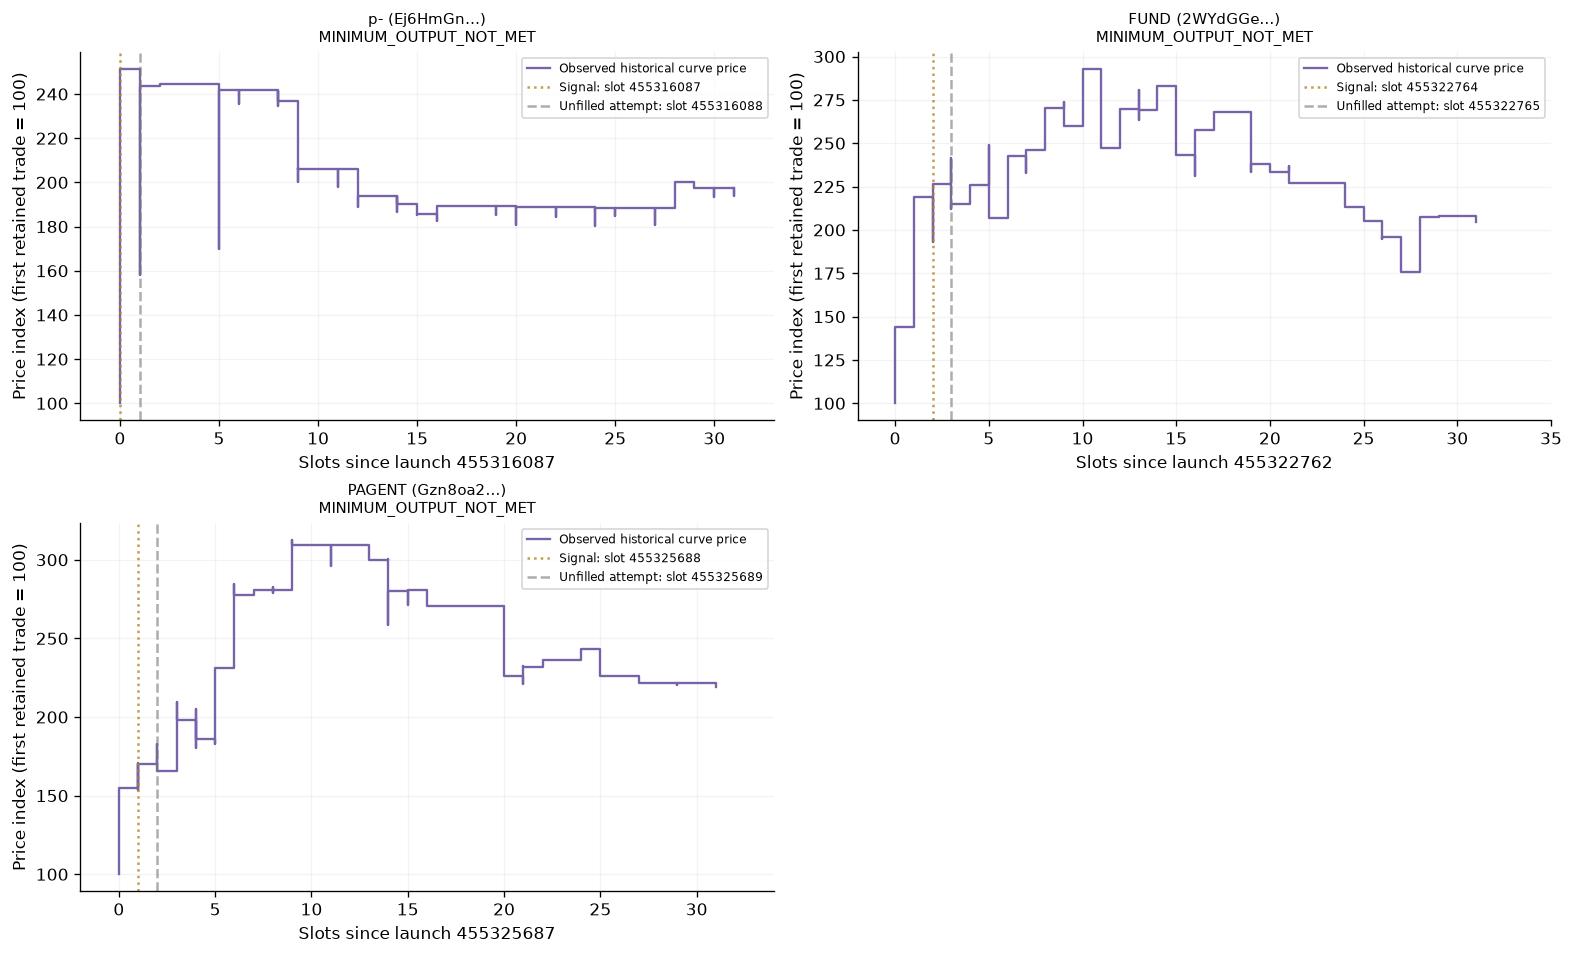

## Entry rejected: 17 signals

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,gmgn_url
PAYROLL,Entry rejected,RISK_REJECTED,455319609,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
ECX,Entry rejected,RISK_REJECTED,455320465,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
PAYROLL,Entry rejected,RISK_REJECTED,455322673,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
BETDRONE,Entry rejected,RISK_REJECTED,455324158,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
STOR,Entry rejected,RISK_REJECTED,455325518,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
MASCHINA,Entry rejected,RISK_REJECTED,455325537,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
PONZI,Entry rejected,RISK_REJECTED,455326046,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
DONT,Entry rejected,RISK_REJECTED,455326076,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
毒チワワ,Entry rejected,RISK_REJECTED,455326949,,,,,0.000000000,—,0.000000000,0.000000000,GMGN
TOGA,Entry rejected,RISK_REJECTED,455327461,,,,,0.000000000,—,0.000000000,0.000000000,GMGN


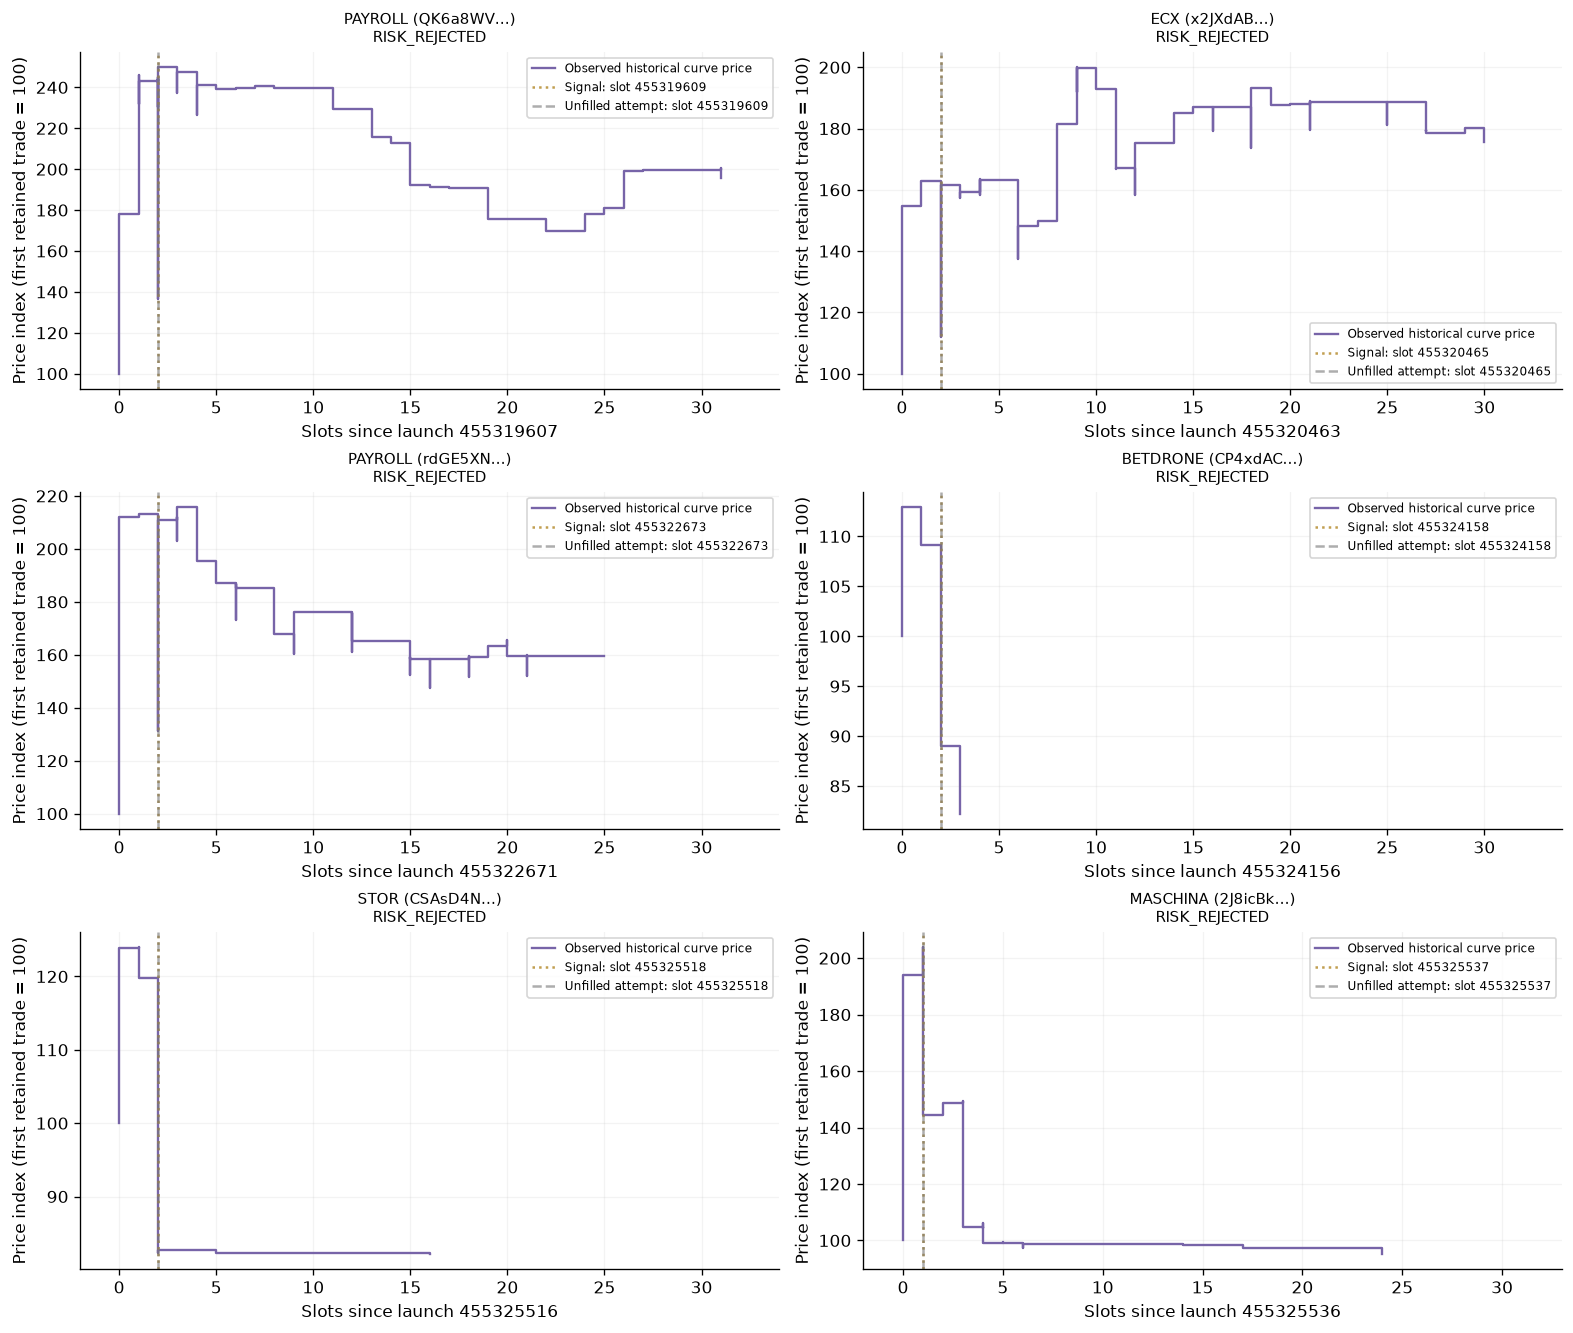

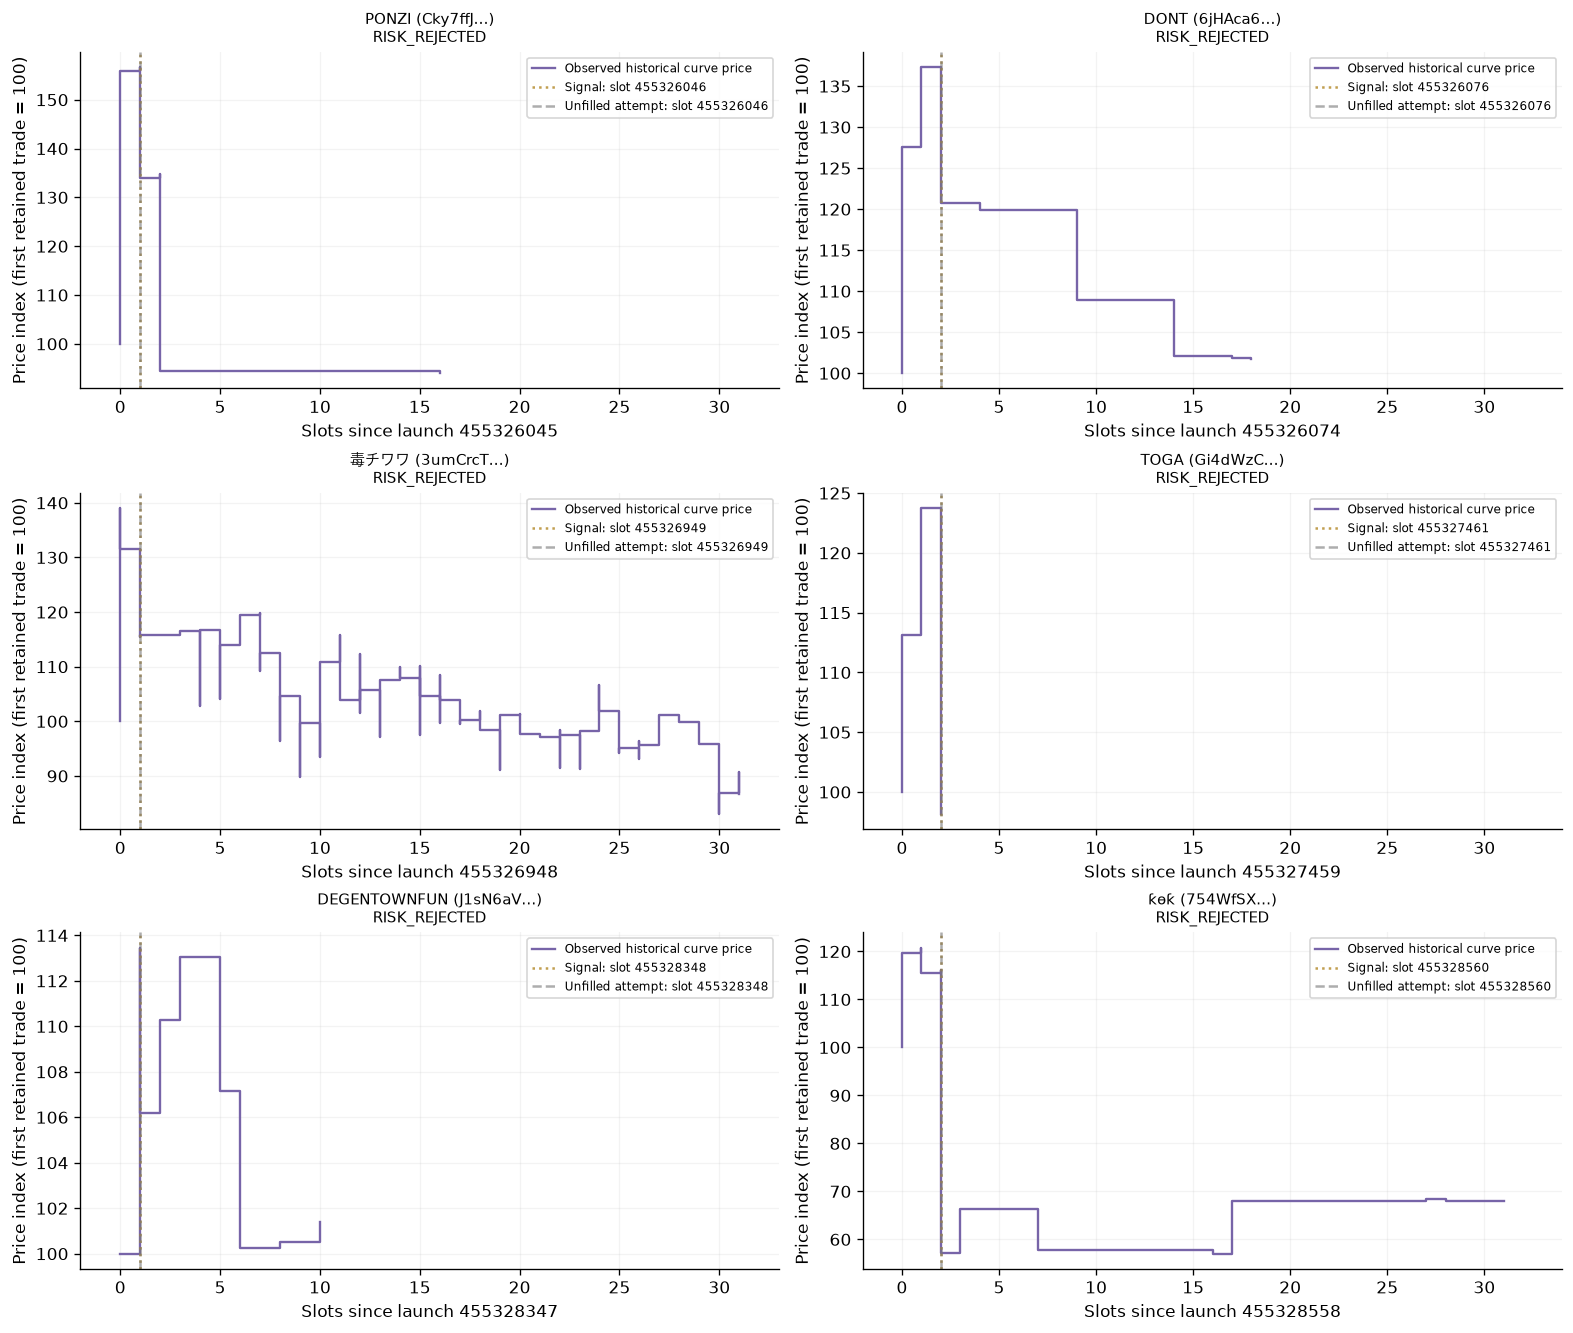

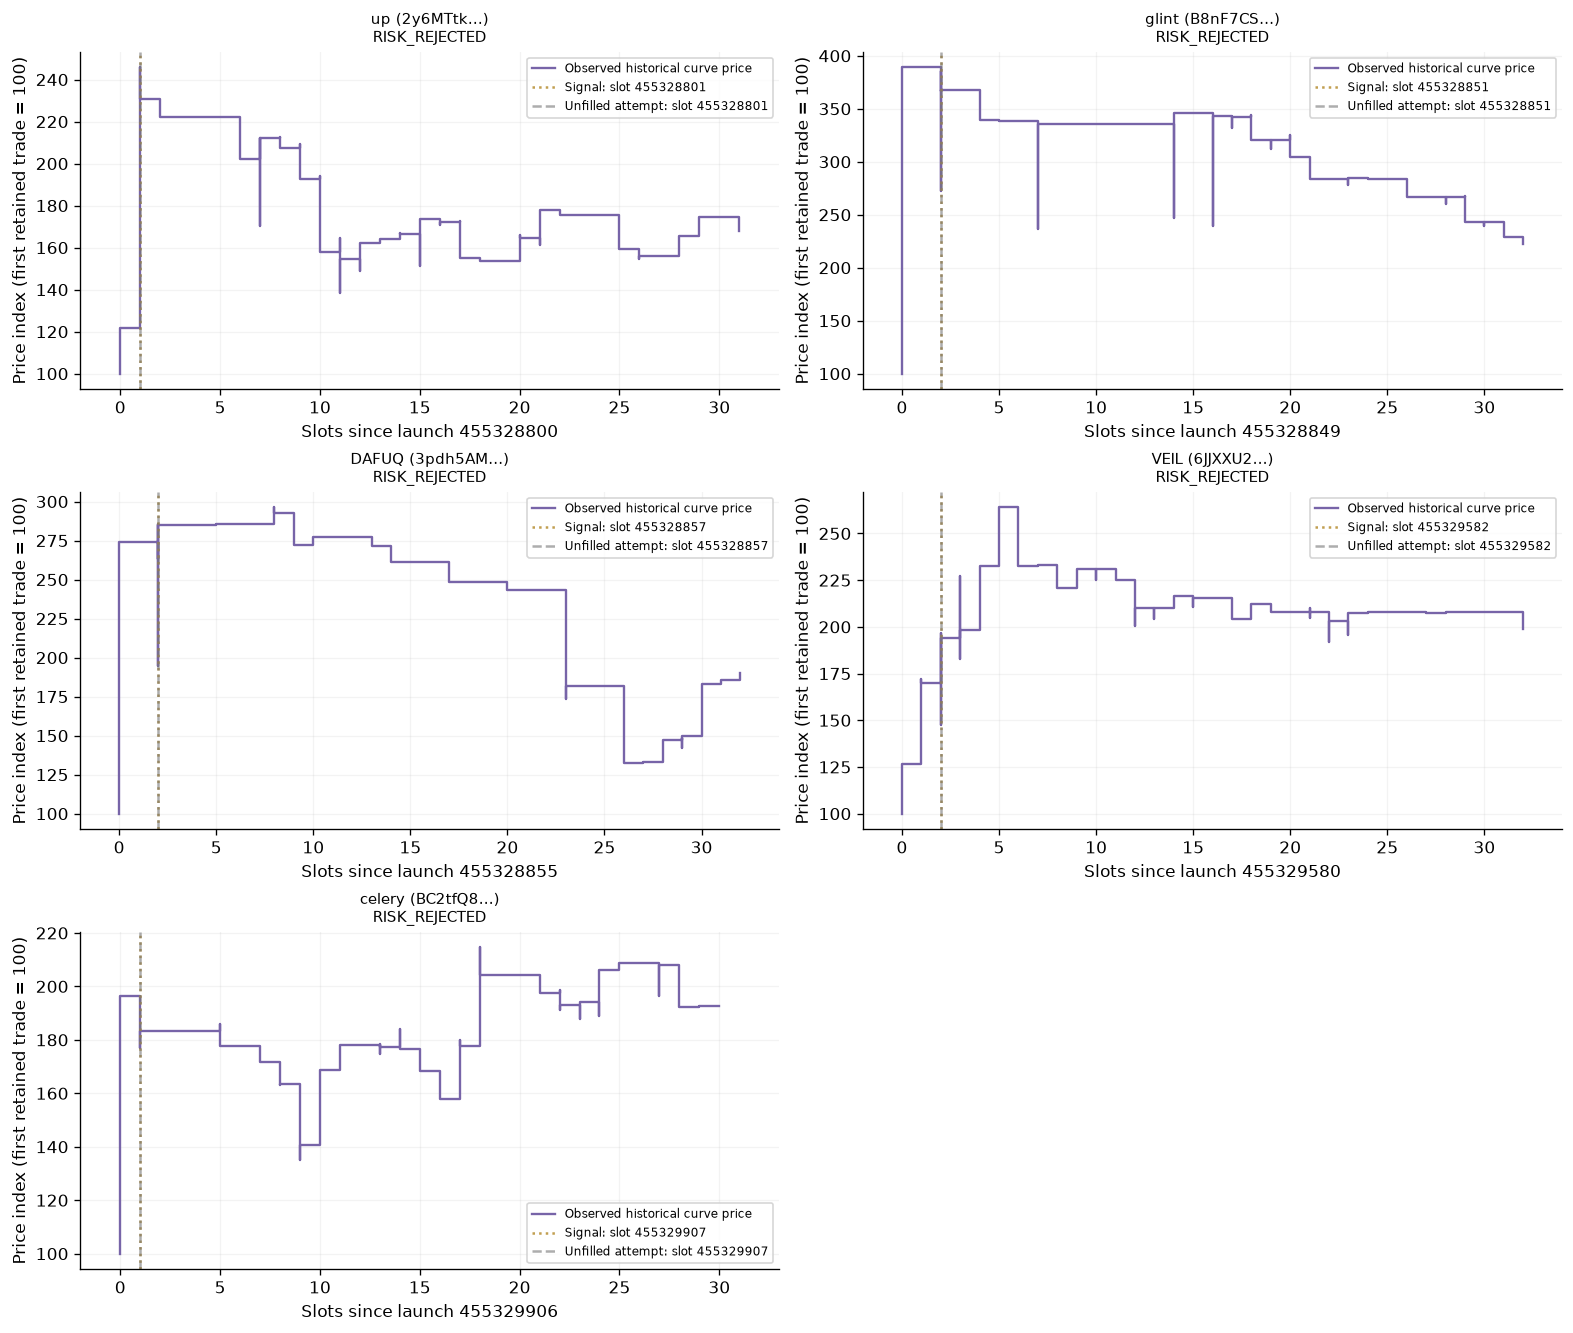

In [13]:
attempt_mints=[]
for group in ['Entry failed','Entry rejected']:
    frame=ENTRY_EXIT[ENTRY_EXIT['group']==group]
    display(Markdown(f'## {group}: {len(frame)} signals'))
    linked_table(frame[entry_exit_view])
    for offset in range(0,len(frame),6):
        page=frame.iloc[offset:offset+6]
        fig,axes=plt.subplots(3,2,figsize=(13,11),layout='constrained')
        for ax,row in zip(axes.flat,page.itertuples()):
            attempt_mints.append(row.mint)
            end,markers=draw_entry_exit(ax,RUN,row.mint)
            assert markers.empty
            ax.set_title(row.token+' ('+row.mint[:7]+'…)\n'+row.reason,fontsize=9)
            ax.legend(fontsize=7)
        for ax in list(axes.flat)[len(page):]:ax.set_visible(False)
        filename='attempts-'+group.lower().replace(' ','-')+f'-{offset//6+1}.png'
        finish_plot(fig,filename)
assert len(attempt_mints)==20 and set(attempt_mints).isdisjoint(c['mint'] for c in chart_records)
gallery_mints=[c['mint'] for c in chart_records]+attempt_mints
assert len(gallery_mints)==38 and set(gallery_mints)==set(positions['mint'])

## Original strategy under other execution assumptions

Every row below uses the original entry/exit rules and this first cohort.
Strict historical reserves and virtual settlement keep historical prices;
virtual settlement adds assumed liquidity. Conditional models carry own reserve
effects and use fixed historical sell quantities or observed sell fractions.
They differ in fills and unresolved outcomes. These are alternate scenarios,
not strategy revisions, and their PnLs are never added together.

In [14]:
scenario_names=['development-baseline','development-strict-before',
                'development-conditional_fixed-before','development-conditional_fraction-before']
scenarios=pd.read_csv(RUN_ROOT/'before_after.csv')
scenarios=scenarios[scenarios['run'].isin(scenario_names)]
assert len(scenarios)==4 and set(scenarios['cohort_start_utc'])=={'2026-10-10T16:00:00Z'}
display(scenarios[['run','execution_mode','counterpart_sell_fraction','net_closed_pnl_SOL',
                   'filled','closed','open','open_cost_SOL','synthetic_shortfall_SOL']])

,run,execution_mode,counterpart_sell_fraction,net_closed_pnl_SOL,filled,closed,open,open_cost_SOL,synthetic_shortfall_SOL
8,development-baseline,EXOGENOUS_VIRTUAL_SETTLEMENT,0,-3.759502,27,27,0,0.000000,7.942451
10,development-conditional_fixed-before,CONDITIONAL_PROTOCOL_REPLAY,0,0.117201,9,2,7,9.578980,0.000000
12,development-conditional_fraction-before,CONDITIONAL_PROTOCOL_REPLAY,1,-1.150398,18,12,6,8.731632,0.000000
17,development-strict-before,EXOGENOUS_REPLAY,0,0.433958,22,15,7,9.701283,0.000000


## Coverage and reproduction

Retained finalized empty-block evidence explains the publication interval at
slot 455328000. The main native result has no other publication gaps. Decoded
scope does not prove complete transfers or exact holders. Counterparty
inventory/slippage, reactions and landing remain modeled. Network/rent charges
are configured scenarios and tips are zero. Full per-observation strategy
traces were not enabled; recorded signal snapshots and native order logs are
shown without inventing missing decisions.

Use **Python 3.13.12 (Sniper research)** in VS Code. Saved outputs can be viewed
without running a kernel. Rerunning writes local CSV/PNG evidence only.

In [15]:
positions.to_csv(EXPORT/'original_all_signals.csv',index=False)
ENTRY_EXIT.to_csv(EXPORT/'all_positions_entry_exit.csv',index=False)
FILL_MARKERS.to_csv(EXPORT/'native_fill_markers.csv',index=False)
pd.DataFrame(chart_records).to_csv(EXPORT/'full_position_chart_index.csv',index=False)
for group,frame in ENTRY_EXIT.groupby('group'):
    frame.to_csv(EXPORT/('positions_'+group.lower().replace(' ','_')+'.csv'),index=False)
buys.to_csv(EXPORT/'original_filled_buys.csv',index=False)
SUMMARY.to_csv(EXPORT/'original_summary.csv',index=False)
events.to_csv(EXPORT/'original_pnl_events.csv',index=False)
LEDGERS[RUN].to_csv(EXPORT/'original_cash_events.csv',index=False)
POSTINGS[RUN].to_csv(EXPORT/'original_ledger_postings.csv',index=False)
scenarios.to_csv(EXPORT/'original_execution_scenarios.csv',index=False)
for label in ['Profitable','Losing','Entry failed','Entry rejected','Open / unresolved']:
    positions[positions['outcome']==label].to_csv(EXPORT/('original_'+label.lower().replace(' / ','_').replace(' ','_')+'.csv'),index=False)
receipt=dict(complete=True,strategy='original',cohort_start_utc='2026-10-10T16:00:00Z',
             cohort_end_utc='2026-10-10T17:00:00Z',selected_runs=RUN_IDS,
             native_result_hashes={n:sha(RUN_ROOT/n/'result.json') for n in RUN_IDS},
             source_manifest_hashes=SOURCE_HASHES,all_native_ledgers_conserve=True,
             all_cash_and_position_contributions_reconcile=True,original_policy_verified=True,
             signals=len(positions),filled_buys=len(buys),gallery_token_count=len(gallery_mints),
             full_position_chart_count=len(chart_records),native_buy_markers=int((FILL_MARKERS['side']=='BUY').sum()),
             native_sell_markers=int((FILL_MARKERS['side']=='SELL').sum()),
             position_groups=ENTRY_EXIT['group'].value_counts().to_dict(),
             closed_contribution_lamports=RESULT['summary']['realized_net_pnl_lamports'],
             open_cost_lamports=RESULT['summary']['open_cash_cost_lamports'],
             full_portfolio_pnl_lamports=None,
             output_hashes={str(p.relative_to(EXPORT)):sha(p) for p in sorted(EXPORT.rglob('*')) if p.suffix in ['.csv','.png']})
(EXPORT/'receipt.json').write_text(json.dumps(receipt,indent=2)+'\n')
print('Original strategy only: scope, all 38 signals, 18 buys, ledger and PnL totals verified.')

Original strategy only: scope, all 38 signals, 18 buys, ledger and PnL totals verified.
